# 12 — El clima completo y la demanda de triage

## Qué se investiga y por qué importa

La pregunta es si un cambio en el clima de Manizales anticipa un aumento de las solicitudes de triage del
hospital, y por qué mecanismo. La hipótesis de trabajo es la de una cadena: un cambio de clima (lo que cuenta es la
**transición**, por ejemplo el paso de una temporada seca a una lluviosa, y no el nivel de lluvia) altera la
incidencia de enfermedad respiratoria en la ciudad con un rezago de días a semanas, y esa presión llega a urgencias,
con más fuerza en las edades en que el clima pesa más.

Una primera medición de esta pregunta barrió 77 variables de clima contra el triage total semanal, con rezagos de
0 a 8 semanas, y concluyó que el clima no predice el triage. Ese diseño no podía sostener esa conclusión, por tres
razones que este cuaderno corrige:

1. **Dilución.** El total mezcla edades con estaciones opuestas (los niños tienen una amplitud estacional de 87 puntos
   y los adultos de 15 a 20) y diluye un efecto que actúa sobre una parte.
2. **Rezago cero.** La mayoría de las pruebas que sobrevivieron eran de la misma semana. Un efecto contemporáneo no
   puede ser contagio y tampoco sirve para anticipar: el mecanismo propuesto exige días de incubación y de decisión.
3. **La comparación contra el azar era ingenua.** Se contaban los «hallazgos» frente al 5 % de las pruebas, y esa
   cuenta supone pruebas independientes. Las variables de clima están muy correlacionadas entre sí y el desenlace
   tiene memoria, así que el azar produce muchos más «hallazgos» de los que da la cuenta del 5 %.

## Qué se hace aquí

1. **Inventario** del clima disponible y de su calidad, con la lluvia comparada solo contra el pluviómetro válido.
2. **Reproducción del barrido original** y medición de lo que el azar habría dado, desplazando en círculo el desenlace
   para conservar su autocorrelación y la estructura del clima.
3. **El mismo barrido con el reloj del mecanismo**: rezagos de 1 a 5 semanas, con efectos fijos de mes, **por banda de
   edad** y con dos familias de variables (el consenso de clima 2020-2026 y el clima completo desde 2010).
4. **Estados del clima** (componentes principales) contra cada desenlace.
5. **El desenlace intermedio respiratorio**: la IRA de Manizales, que cubre 13 años, y su puente hacia el triage.
6. **Episodios concretos**: los fines de sequía y las semanas muy lluviosas, con una prueba de colocación.
7. **El estado de hoy**, descriptivo.

El criterio de evidencia es el mismo en todo el cuaderno. Cada hallazgo se **descubre** en 2022-03 a 2024-12 y se
**confirma** en 2025-01 a 2026-08, con la misma variable, el mismo rezago y el mismo signo. Y el número de hallazgos se
compara siempre con la distribución que da el azar, no con el 5 % nominal.

**El desenlace** es el de `notebooks/desenlace.py`: log del triage semanal sin calendario y sin los cortes de nivel de
la red de salud (Nueva EPS), conservando la estacionalidad, porque el clima puede explicarla. Las semanas son
epidemiológicas, de domingo a sábado. Para las bandas de edad se aplica el mismo tratamiento a cada serie.

## De dónde salen los datos

| Qué | Archivo | Fuente |
|---|---|---|
| Clima diario unificado, 2020-2026 (consenso de cuatro fuentes, pluviómetro roto ya quitado) | `calendarios/clima_unificado.csv.gz` | IDEAM, METAR La Nubia, NASA POWER, Open-Meteo |
| Clima completo desde 2010: horas de sol, nubosidad, déficit de presión de vapor, rachas y transiciones | `calendarios/clima_completo.csv.gz` | Open-Meteo (ERA5) y NASA POWER |
| METAR del aeropuerto La Nubia | `calendarios/clima/raw_iem_skmz.csv` | Iowa Environmental Mesonet |
| Reanálisis MERRA-2 y satélite, celda de ~55 km | `calendarios/clima/raw_nasapower.csv` | NASA POWER |
| Reanálisis ERA5-Land / ERA5 | `calendarios/clima/raw_openmeteo.csv` | Open-Meteo |
| Estaciones IDEAM empalmadas | `calendarios/clima/clima_ideam.csv` | IDEAM |
| Triage diario y por banda de edad | `salidas/triage_diario.parquet`, `salidas/triage_edad.parquet` | agregados del hospital, sin dato personal |
| Egresos por capítulo CIE-10 | `salidas/perfil_dx_diario.parquet` | agregados del hospital |
| IRA de Manizales (consultas externas y de urgencias, por semana) | `calendarios/vigilancia_sivigila.csv.gz` | SIVIGILA, evento 995 |

La construcción del consenso de clima y sus controles de calidad están en `calendarios/docs/CLIMA.md`. Este cuaderno
no se conecta a la base del hospital.

In [1]:
import sys, pathlib, warnings, os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")   # silencia un aviso de scikit-learn en Windows
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "notebooks")); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from sklearn.decomposition import PCA
from desenlace import desenlace_semanal

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
CATEG = [AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO]
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
DIVERGENTE = LinearSegmentedColormap.from_list("div", [AZUL, "#f0efec", ROJO])
SECUENCIAL = LinearSegmentedColormap.from_list("sec", ["#f0efec", AZUL])
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 120)

DESC = ("2022-03-06", "2024-12-29")      # descubrir (el de desenlace.py)
CONF = ("2025-01-05", "2026-08-23")      # confirmar: el clima termina el 2026-08-28
CLIMA_REF = ("2020-01-01", "2024-12-31") # climatologia y percentiles: nunca con datos de confirmar
REZAGOS = range(0, 9)
Q_BH = 0.10

def a_semana(s, como="mean", minimo=6):
    """Semana epidemiologica (domingo a sabado), indexada por el domingo. Nula si la semana tiene pocos dias."""
    g = s.resample("W-SAT"); r = getattr(g, como)(); n = g.count()
    r = r.where(n >= minimo); r.index = r.index - pd.Timedelta(days=6)
    return r

def pct(b): return 100 * (np.exp(b) - 1)

cl = pd.read_csv(RAIZ / "calendarios/clima_unificado.csv.gz", parse_dates=["fecha"]).set_index("fecha").asfreq("D")
Y = desenlace_semanal()
print(f"clima: {cl.index.min():%Y-%m-%d} a {cl.index.max():%Y-%m-%d}, {len(cl)} días, {cl.shape[1]} columnas")
print(f"desenlace: {Y.index.min():%Y-%m-%d} a {Y.index.max():%Y-%m-%d}; semanas con y -> descubrir {Y.y.loc[DESC[0]:DESC[1]].notna().sum()}, "
      f"confirmar {Y.y.loc[CONF[0]:CONF[1]].notna().sum()}; secundarios: {[c for c in Y if c.startswith('y_')]}")

import time
from scipy.stats import norm
import desenlace as de
import indices as ix
N_SIM = 300                              # desplazamientos circulares del desenlace para construir lo que daría el azar
REZ_MEC = range(1, 6)                    # rezagos de 1 a 5 semanas: el reloj del contagio y de la decisión de consultar
BANDAS = {"0-4": "0 a 4 años", "5-14": "5 a 14 años", "15-44": "15 a 44 años", "45-64": "45 a 64 años", "65-+": "65 años y más"}

clima: 2020-01-01 a 2026-08-28, 2432 días, 68 columnas
desenlace: 2022-03-06 a 2026-09-13; semanas con y -> descubrir 147, confirmar 86; secundarios: ['y_respiratorio', 'y_infecciosas', 'y_trauma']


---
# 1. Inventario: qué clima hay y cuánto se puede confiar en él

Cada renglón es una variable de una fuente, con su cobertura entre el 2020-01-01 y el 2026-08-28 y su papel en el consenso.
Después se compara la calidad de la lluvia, que es lo delicado: cada fuente se contrasta con el pluviómetro **solo en los
días en que el pluviómetro es válido**.

In [2]:
periodo = pd.date_range("2020-01-01", "2026-08-28")
leer = lambda n: pd.read_csv(RAIZ / f"calendarios/clima/{n}", parse_dates=["fecha"]).drop_duplicates("fecha").set_index("fecha").reindex(periodo)
iem, nasa, om, ideam = leer("raw_iem_skmz.csv"), leer("raw_nasapower.csv"), leer("raw_openmeteo.csv"), leer("clima_ideam.csv")
def fila(fuente, variable, s, uso):
    s = s.reindex(periodo)
    return {"fuente": fuente, "variable": variable, "desde": f"{s.first_valid_index():%Y-%m}" if s.notna().any() else "—",
            "hasta": f"{s.last_valid_index():%Y-%m}" if s.notna().any() else "—", "% días": round(100 * s.notna().mean(), 1), "uso en el consenso": uso}
pluvio = cl.precipitacion_mm.where(cl.precip_con_estacion & ~cl.pluviometro_fallido)
inv = pd.DataFrame([
    fila("IDEAM (3 estaciones)", "lluvia de pluviómetro válida", pluvio, "referencia de lluvia"),
    fila("IDEAM (3 estaciones)", "temperatura media (hasta 24 lecturas/día)", ideam.temp_media.where(ideam.estacion_clima.ne("PLANALTO")), "referencia de la media (sin Planalto)"),
    fila("METAR La Nubia (IEM)", "temperatura máxima y mínima", iem.iem_tmax_c, "referencia de máx. y mín."),
    fila("METAR La Nubia (IEM)", "humedad relativa mín. y máx.", iem.iem_hr_min, "fuente secundaria"),
    fila("METAR La Nubia (IEM)", "punto de rocío máx. y mín.", iem.max_dwpf, "no entra"),
    fila("METAR La Nubia (IEM)", "viento medio", iem.avg_sknt, "referencia del viento"),
    fila("METAR La Nubia (IEM)", "sensación térmica", iem.avg_feel, "no entra (función de temp. y viento)"),
    fila("METAR La Nubia (IEM)", "lluvia", iem.precip, "vacía"),
    fila("NASA POWER (~55 km)", "temperatura media, máx. y mín.", nasa.np_T2M, "fuente secundaria"),
    fila("NASA POWER (~55 km)", "humedad relativa media", nasa.np_RH2M, "referencia de humedad"),
    fila("NASA POWER (~55 km)", "punto de rocío medio", nasa.np_T2MDEW, "no hay consenso: se usa tal cual"),
    fila("NASA POWER (~55 km)", "lluvia", nasa.np_PRECTOTCORR, "relleno escalado donde no hay pluviómetro"),
    fila("NASA POWER (~55 km)", "viento a 2 m", nasa.np_WS2M, "fuente secundaria"),
    fila("NASA POWER (~55 km)", "radiación solar", nasa.np_ALLSKY_SFC_SW_DWN, "única fuente real de la radiación"),
    fila("Open-Meteo (ERA5-Land)", "temperatura media, máx. y mín.", om.om_temperature_2m_mean, "fuente secundaria"),
    fila("Open-Meteo (ERA5-Land)", "humedad relativa media", om.om_relative_humidity_2m_mean, "fuente secundaria"),
    fila("Open-Meteo (ERA5, ~28 km)", "lluvia", om.om_precipitation_sum, "excluida (ver tabla de lluvia)"),
    fila("Open-Meteo (ERA5, ~28 km)", "horas de lluvia", om.om_precipitation_hours, "no entra al consenso"),
    fila("Open-Meteo", "viento, radiación, evapotranspiración", om.om_wind_speed_10m_max, "columnas vacías"),
])
print("radiación del consenso = NASA POWER exactamente:", bool((cl.radiacion_consenso - cl.np_ALLSKY_SFC_SW_DWN).abs().max() == 0))
inv

radiación del consenso = NASA POWER exactamente:

 True


,fuente,variable,desde,hasta,% días,uso en el consenso
0,IDEAM (3 estaciones),lluvia de pluviómetro válida,2020-01,2026-08,34.7,referencia de lluvia
1,IDEAM (3 estaciones),temperatura media (hasta 24 lecturas/día),2020-01,2026-08,46.4,referencia de la media (sin Planalto)
2,METAR La Nubia (IEM),temperatura máxima y mínima,2020-01,2026-08,82.9,referencia de máx. y mín.
3,METAR La Nubia (IEM),humedad relativa mín. y máx.,2020-01,2026-08,83.0,fuente secundaria
4,METAR La Nubia (IEM),punto de rocío máx. y mín.,2020-01,2026-08,83.0,no entra
5,METAR La Nubia (IEM),viento medio,2020-01,2026-08,75.0,referencia del viento
6,METAR La Nubia (IEM),sensación térmica,2020-01,2026-08,77.5,no entra (función de temp. y viento)
7,METAR La Nubia (IEM),lluvia,—,—,0.0,vacía
8,NASA POWER (~55 km),"temperatura media, máx. y mín.",2020-01,2026-08,99.8,fuente secundaria
9,NASA POWER (~55 km),humedad relativa media,2020-01,2026-08,99.8,referencia de humedad


In [3]:
# ---- ¿Qué fuente de lluvia se parece al pluviómetro? Solo días con pluviómetro válido.
v = pluvio.notna()
fuentes = {"pluviómetro IDEAM": cl.precipitacion_mm, "NASA POWER": cl.np_PRECTOTCORR, "Open-Meteo, lluvia": cl.om_precipitation_sum,
           "Open-Meteo, horas de lluvia": cl.om_precipitation_hours, "consenso": cl.precip_consenso_mm}
semana_valida = a_semana(v.astype(float), "sum", 1) == 7
filas = []
for nom, s in fuentes.items():
    d = s[v]; w = a_semana(s.where(v), "sum", 7)[semana_valida]; wp = a_semana(pluvio, "sum", 7)[semana_valida]
    es_h = "horas" in nom
    filas.append({"fuente": nom, "media anual (mm)": None if es_h else round(365 * d.mean()),
                  "% días ≥ 1 mm": None if es_h else round(100 * (d >= 1).mean(), 1),
                  "horas/día (mediana)": round(d.median(), 1) if es_h else None,
                  "r diario con pluviómetro": round(d.corr(pluvio[v]), 2), "r semanal con pluviómetro": round(w.corr(wp), 2)})
print(f"{int(v.sum())} días con pluviómetro válido; {int(semana_valida.sum())} semanas completas con pluviómetro")
display(pd.DataFrame(filas).set_index("fuente"))
# ---- la racha seca se mide con el consenso: ¿los días secos dependen de la fuente del día?
seco = (cl.precip_consenso_mm < 1)
t = seco.groupby([cl.index.year, np.where(v, "con pluviómetro", "sin pluviómetro (NASA escalado)")]).mean().unstack().mul(100).round(1)
t.index.name = "% de días secos (< 1 mm) en el consenso"
t

844 días con pluviómetro válido; 77 semanas completas con pluviómetro


,media anual (mm),% días ≥ 1 mm,horas/día (mediana),r diario con pluviómetro,r semanal con pluviómetro
fuente,,,,,
pluviómetro IDEAM,1352.0,43.0,NaN,1.00,1.00
NASA POWER,1969.0,78.6,NaN,0.30,0.46
"Open-Meteo, lluvia",16621.0,97.6,NaN,-0.02,0.01
"Open-Meteo, horas de lluvia",NaN,NaN,24.0,0.06,0.18
consenso,1352.0,66.0,NaN,0.90,0.92


,con pluviómetro,sin pluviómetro (NASA escalado)
% de días secos (< 1 mm) en el consenso,,
2020,43.6,49.8
2021,NaN,54.8
2022,22.1,19.1
2023,33.3,34.8
2024,36.4,34.4
2025,32.6,14.9
2026,45.5,24.6


**Hay menos clima independiente del que parece.** De las 68 columnas del archivo unificado, las medidas en tierra son pocas
y cubren poco:

| Medida en tierra | % de días |
|---|---|
| Lluvia de pluviómetro válida | **34,7** |
| Temperatura media IDEAM (sin Planalto) | 46,4 |
| Máxima y mínima del METAR | 82,9 |
| Viento del METAR | 75,0 |

El resto es reanálisis: NASA POWER cubre el 99,8 % de los días y Open-Meteo el 99,3 %. La radiación del consenso es
exactamente la de NASA POWER, porque Open-Meteo trae vacías la radiación, el viento y la evapotranspiración, y el METAR no
trae lluvia.

**Calidad de la lluvia**, en los 844 días con pluviómetro válido:

| Fuente | mm/año | % días ≥ 1 mm | r diario | r semanal |
|---|---|---|---|---|
| Pluviómetro IDEAM | 1.352 | 43,0 | 1 | 1 |
| NASA POWER | 1.969 | 78,6 | 0,30 | 0,46 |
| Open-Meteo, lluvia | 16.621 | 97,6 | −0,02 | 0,01 |
| Open-Meteo, horas de lluvia | mediana de 24 h/día | — | 0,06 | 0,18 |
| Consenso | 1.352 | 66,0 | 0,90 | 0,92 |

- Las horas de lluvia de Open-Meteo no sirven: la mediana es de 24 horas al día y la correlación semanal con el pluviómetro es 0,18.
  Quedan fuera de los índices.
- La lluvia de Open-Meteo es ruido, como ya documentaba el análisis de la fuente.
- El consenso acierta el total (1.352 mm; r semanal 0,92) pero marca lluvia el 66,0 % de los días cuando el pluviómetro la
  marca el 43,0 %: la mediana de dos fuentes promedia el pluviómetro con la llovizna de NASA. Por eso **la racha seca del
  consenso sale más corta que la real y depende de la fuente de cada día**: en 2025 los días secos son el 32,6 % con
  pluviómetro y el 14,9 % sin él; en 2026, el 45,5 % y el 24,6 %. La racha seca es la variable menos fiable del
  conjunto, y la lluvia se usa en acumulados semanales y de 4 y 8 semanas, donde el total es robusto.
- 2021 no tiene ni un día con pluviómetro. No entra en las pruebas: el periodo de descubrir empieza en 2022-03 y el rezago
  máximo llega a enero de 2022.

---
# 2. Las variables derivadas, por semana

**Once variables base**, del consenso salvo donde no lo hay:
- temperatura media, máxima y mínima;
- amplitud térmica (máxima − mínima);
- humedad;
- punto de rocío (NASA POWER);
- lluvia (suma de la semana, es decir, un acumulado de 7 días);
- horas de lluvia (Open-Meteo);
- viento;
- radiación (NASA POWER);
- **racha seca**: días seguidos con < 1 mm al cierre de la semana, que puede pasar de 7.

**Cada una en cinco formas:** el nivel, la anomalía contra lo normal de ese mes y el cambio a 1, 2 y 4 semanas. Los
cambios son la forma de la **transición**.

**Extremos:** los días de la semana por encima del p90 o por debajo del p10 de su mes. Para la lluvia, días > p90 y días
secos (< 1 mm), porque su p10 es cero.

**La temporada:** lluvia acumulada de 4 y 8 semanas en % sobre lo normal para el mes, y su **giro**, que es el cambio frente
a 4 u 8 semanas antes, en puntos porcentuales. Es la forma de la transición de seco a lluvioso a escala de temporada.

La climatología y los percentiles salen solo de 2020-2024, así que el periodo de confirmar nunca se usa para definir lo
«normal».

In [4]:
dia = cl.loc["2020-01-01":"2026-08-28"]
diarias = pd.DataFrame({
    "temp. media": dia.temp_media_consenso, "temp. máxima": dia.temp_max_consenso, "temp. mínima": dia.temp_min_consenso,
    "amplitud térmica": dia.temp_max_consenso - dia.temp_min_consenso, "humedad": dia.humedad_consenso,
    "punto de rocío": dia.np_T2MDEW, "lluvia": dia.precip_consenso_mm, "horas de lluvia": dia.om_precipitation_hours,
    "viento": dia.viento_consenso_ms, "radiación": dia.radiacion_consenso})
seco_d = (diarias.lluvia < 1).astype(float)
racha_d = seco_d.groupby((seco_d != 1).cumsum()).cumsum().where(diarias.lluvia.notna())   # días seguidos con < 1 mm

SEM = pd.date_range("2020-01-05", "2026-09-13", freq="W-SUN")
nivel = pd.DataFrame({c: a_semana(diarias[c], "sum" if c == "lluvia" else "mean", 7 if c == "lluvia" else 6)
                      for c in diarias}).reindex(SEM)
nivel["racha seca"] = a_semana(racha_d, "last", 1).reindex(SEM)          # al cierre de la semana; puede pasar de 7
mes = pd.Series((SEM + pd.Timedelta(days=3)).month, index=SEM)          # el mes de la mitad de la semana
ref = (SEM >= CLIMA_REF[0]) & (SEM <= CLIMA_REF[1])
clim = nivel[ref].groupby(mes[ref]).mean()
anom = nivel - clim.reindex(mes.values).values

# extremos: días de la semana por encima del p90 (o por debajo del p10) de su mes, percentiles de 2020-2024
ref_d = diarias.loc[CLIMA_REF[0]:CLIMA_REF[1]]
p90 = ref_d.groupby(ref_d.index.month).quantile(.9).reindex(diarias.index.month).set_axis(diarias.index)
p10 = ref_d.groupby(ref_d.index.month).quantile(.1).reindex(diarias.index.month).set_axis(diarias.index)
dias_sem = lambda b: (7 * a_semana(b.astype(float).where(diarias[b.name].notna()), "mean", 6)).reindex(SEM)

X = {}
for c in nivel:
    X[(c, "nivel")] = nivel[c]; X[(c, "anomalía")] = anom[c]
    for k in (1, 2, 4): X[(c, f"cambio {k} sem")] = nivel[c].diff(k)
for c in ["temp. media", "temp. máxima", "temp. mínima", "amplitud térmica", "humedad", "punto de rocío", "viento", "radiación"]:
    X[(c, "días > p90")] = dias_sem((diarias[c] > p90[c]).rename(c))
    X[(c, "días < p10")] = dias_sem((diarias[c] < p10[c]).rename(c))
X[("lluvia", "días > p90")] = dias_sem((diarias.lluvia > p90.lluvia).rename("lluvia"))
X[("lluvia", "días secos")] = dias_sem((diarias.lluvia < 1).rename("lluvia"))

# temporada: lluvia acumulada de 4 y 8 semanas en % sobre lo normal para ese mes, y su giro (fin_de_sequia)
TEMP = pd.DataFrame(index=SEM)
for k in (4, 8):
    acum = nivel.lluvia.rolling(k).sum()
    normal = acum[ref].groupby(mes[ref]).mean()
    TEMP[f"lluvia {k} sem (% sobre lo normal)"] = 100 * (acum / normal.reindex(mes.values).values - 1)
TEMP["giro 4 sem (pp)"] = TEMP["lluvia 4 sem (% sobre lo normal)"].diff(4)
TEMP["giro 8 sem (pp)"] = TEMP["lluvia 8 sem (% sobre lo normal)"].diff(8)
for c in TEMP: X[("temporada", c)] = TEMP[c]
X = pd.DataFrame(X)
X.loc["2026-08-30":] = np.nan                                          # no hay clima después del 2026-08-28
print(f"{nivel.shape[1]} variables base; {X.shape[1]} variables derivadas; x {len(REZAGOS)} rezagos = {X.shape[1] * len(REZAGOS)} pruebas")
print("cobertura en descubrir+confirmar (% semanas con dato), la más baja:",
      X.loc["2021-12-26":CONF[1]].notna().mean().mul(100).round(1).nsmallest(4).to_dict())
X.columns.get_level_values(1).value_counts().rename("variables por forma").to_frame().T

11 variables base; 77 variables derivadas; x 9 rezagos = 693 pruebas
cobertura en descubrir+confirmar (% semanas con dato), la más baja: {('temp. media', 'nivel'): 99.6, ('temp. media', 'anomalía'): 99.6, ('temp. media', 'cambio 1 sem'): 99.6, ('temp. media', 'cambio 2 sem'): 99.6}


,nivel,anomalía,cambio 1 sem,cambio 2 sem,cambio 4 sem,días > p90,días < p10,días secos,lluvia 4 sem (% sobre lo normal),lluvia 8 sem (% sobre lo normal),giro 4 sem (pp),giro 8 sem (pp)
variables por forma,11,11,11,11,11,9,8,1,1,1,1,1


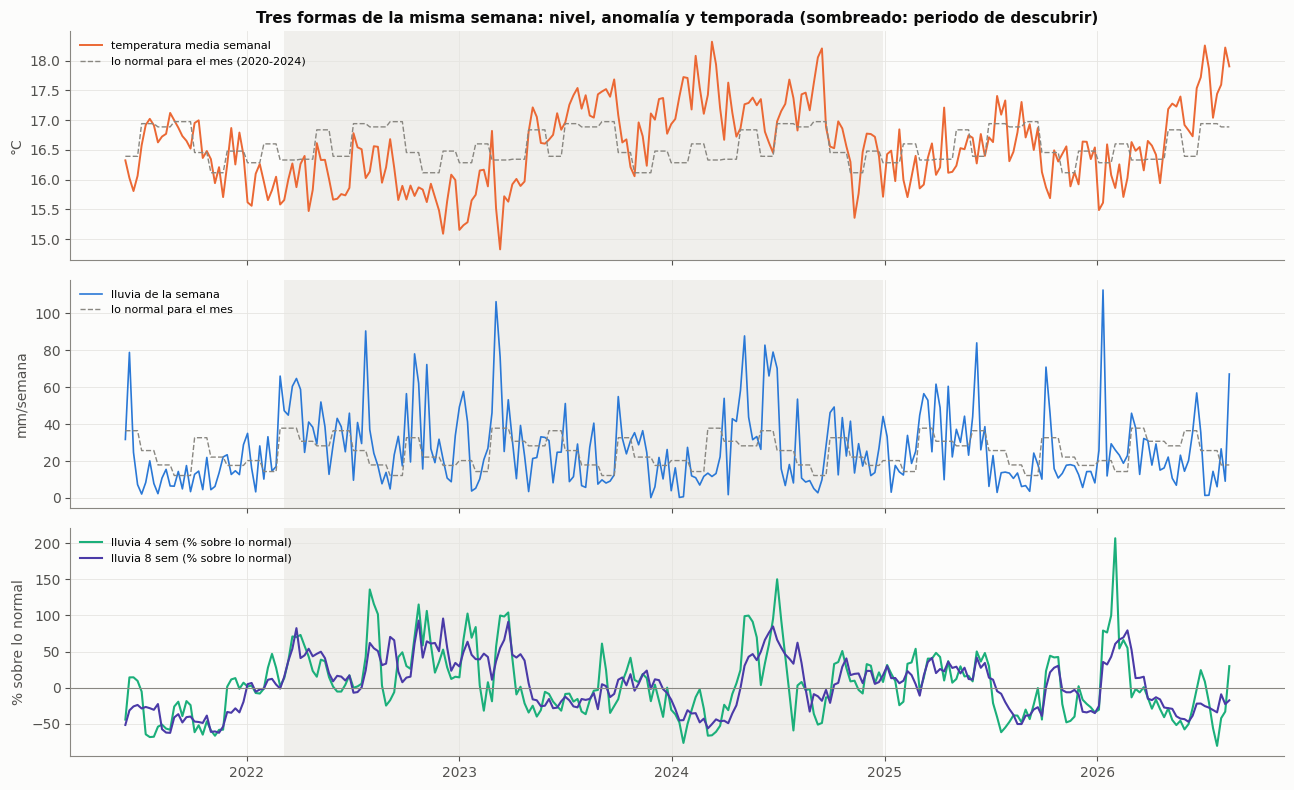

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
w = SEM[(SEM >= "2021-06-01")]
axes[0].plot(w, nivel.loc[w, "temp. media"], color=NARANJA, lw=1.4, label="temperatura media semanal")
axes[0].plot(w, (nivel["temp. media"] - anom["temp. media"]).loc[w], color=MUDO, lw=1, ls="--", label="lo normal para el mes (2020-2024)")
axes[0].set_ylabel("°C"); axes[0].legend(fontsize=8, loc="upper left")
axes[1].plot(w, nivel.loc[w, "lluvia"], color=AZUL, lw=1.2, label="lluvia de la semana")
axes[1].plot(w, (nivel.lluvia - anom.lluvia).loc[w], color=MUDO, lw=1, ls="--", label="lo normal para el mes")
axes[1].set_ylabel("mm/semana"); axes[1].legend(fontsize=8, loc="upper left")
for c, col in [("lluvia 4 sem (% sobre lo normal)", AQUA), ("lluvia 8 sem (% sobre lo normal)", VIOLETA)]:
    axes[2].plot(w, TEMP.loc[w, c], color=col, lw=1.5, label=c)
axes[2].axhline(0, color=MUDO, lw=.8); axes[2].set_ylabel("% sobre lo normal"); axes[2].legend(fontsize=8, loc="upper left")
for ax in axes:
    ax.axvspan(pd.Timestamp(DESC[0]), pd.Timestamp(DESC[1]), color="#f0efec", lw=0, zorder=0)
axes[0].set_title("Tres formas de la misma semana: nivel, anomalía y temporada (sombreado: periodo de descubrir)")
plt.tight_layout(); plt.show()

Son **77 variables derivadas**. La cobertura en 2022-2026 es alta: la variable más incompleta tiene el 99,6 % de las semanas.

La figura muestra por qué se necesitan las tres escalas:
- **La temperatura tiene épocas largas.** 2021 y el arranque de 2022 van fríos; la segunda mitad de 2023 y buena parte de
  2024 van por encima de lo normal, y mediados de 2026 también. Un nivel semanal mezcla la época con la semana.
- **La lluvia semanal es muy ruidosa.** Solo a 4 y 8 semanas aparecen las temporadas: las secas de 2020-2021, la lluviosa de
  2022, la seca de finales de 2023 y comienzos de 2024, el giro lluvioso de enero de 2026 y la seca de 2026, que se corta en agosto.

**Límite.** Lo «normal» de cada mes sale de cinco años (2020-2024), y la figura muestra que esos años tuvieron épocas frías y
cálidas largas. Una anomalía es relativa a ese quinquenio, no a un clima de 30 años.

---
# 3. El barrido original y lo que el azar habría dado

Primero se reproduce el barrido original: para cada variable y cada rezago de 0 a 8 semanas, una regresión del desenlace
sobre la variable, con errores robustos a la autocorrelación (HAC, 4 rezagos). La variable va en desviaciones típicas del
periodo de descubrir, de modo que **el efecto se lee como «% de triage por 1 sd»**. Después, Benjamini-Hochberg con q = 0,10
sobre las 693 pruebas juntas.

In [6]:
def prueba(y, x, extra=None, maxlags=4):
    d = pd.concat([y.rename("y"), x.rename("x")] + ([extra] if extra is not None else []), axis=1).dropna()
    if len(d) < 30 or d.x.std() == 0: return dict(b=np.nan, se=np.nan, p=np.nan, n=len(d))
    Z = sm.add_constant(d.drop(columns="y"))
    m = sm.OLS(d.y, Z).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})
    return dict(b=m.params["x"], se=m.bse["x"], p=m.pvalues["x"], n=len(d))

SD = X.loc[DESC[0]:DESC[1]].std()                      # 1 unidad = 1 desviación típica del periodo de descubrir
Xs = X / SD
def barrer(Xs, y, periodo, rezagos=REZAGOS):
    y = y.loc[periodo[0]:periodo[1]]
    nombre = lambda c: c if isinstance(c, tuple) else (c, "índice")
    return pd.DataFrame([{"variable": nombre(c)[0], "forma": nombre(c)[1], "rezago": k, **prueba(y, Xs[c].shift(k))}
                         for c in Xs.columns for k in rezagos])
B = barrer(Xs, Y.y, DESC)
B["efecto %"] = pct(B.b)
B["sobrevive BH"], B["q"], *_ = multipletests(B.p.fillna(1), alpha=Q_BH, method="fdr_bh")
S = B[B["sobrevive BH"]].copy()
print(f"pruebas: {len(B)} (válidas {B.p.notna().sum()}); p < 0,05 sin corregir: {(B.p < .05).sum()} "
      f"(el azar solo daría ~{round(.05 * B.p.notna().sum())}); sobreviven a BH q = {Q_BH}: {len(S)} pruebas, "
      f"{S[['variable', 'forma']].drop_duplicates().shape[0]} variables derivadas, {S.variable.nunique()} variables base")
print("supervivientes por rezago (semanas):", S.rezago.value_counts().sort_index().to_dict(), "| por signo:", {"+": int((S.b > 0).sum()), "−": int((S.b < 0).sum())})
S.assign(IC95=[f"[{pct(b - 1.96 * s):+.1f}; {pct(b + 1.96 * s):+.1f}]" for b, s in zip(S.b, S.se)]) \
 [["variable", "forma", "rezago", "efecto %", "IC95", "p", "q", "n"]].sort_values("p").round({"efecto %": 1, "p": 5, "q": 4})

pruebas: 693 (válidas 693); p < 0,05 sin corregir: 84 (el azar solo daría ~35); sobreviven a BH q = 0.1: 34 pruebas, 26 variables derivadas, 10 variables base
supervivientes por rezago (semanas): {0: 22, 1: 2, 2: 1, 3: 1, 4: 1, 5: 4, 6: 2, 8: 1} | por signo: {'+': 24, '−': 10}


,variable,forma,rezago,efecto %,IC95,p,q,n
558,amplitud térmica,días < p10,0,-2.0,[-2.8; -1.3],0.00000,0.0000,147
441,radiación,cambio 4 sem,0,2.1,[+1.2; +3.1],0.00001,0.0040,147
144,amplitud térmica,anomalía,0,1.9,[+1.0; +2.7],0.00002,0.0041,147
93,temp. mínima,nivel,3,1.9,[+0.9; +2.9],0.00011,0.0194,147
27,temp. media,cambio 2 sem,0,1.6,[+0.7; +2.4],0.00028,0.0300,147
567,humedad,días > p90,0,-1.5,[-2.3; -0.7],0.00030,0.0300,147
630,radiación,días < p10,0,-1.5,[-2.3; -0.7],0.00030,0.0300,147
180,humedad,nivel,0,-1.6,[-2.5; -0.7],0.00042,0.0316,147
550,amplitud térmica,días > p90,1,1.3,[+0.6; +2.0],0.00042,0.0316,147
189,humedad,anomalía,0,-1.5,[-2.3; -0.7],0.00053,0.0316,147


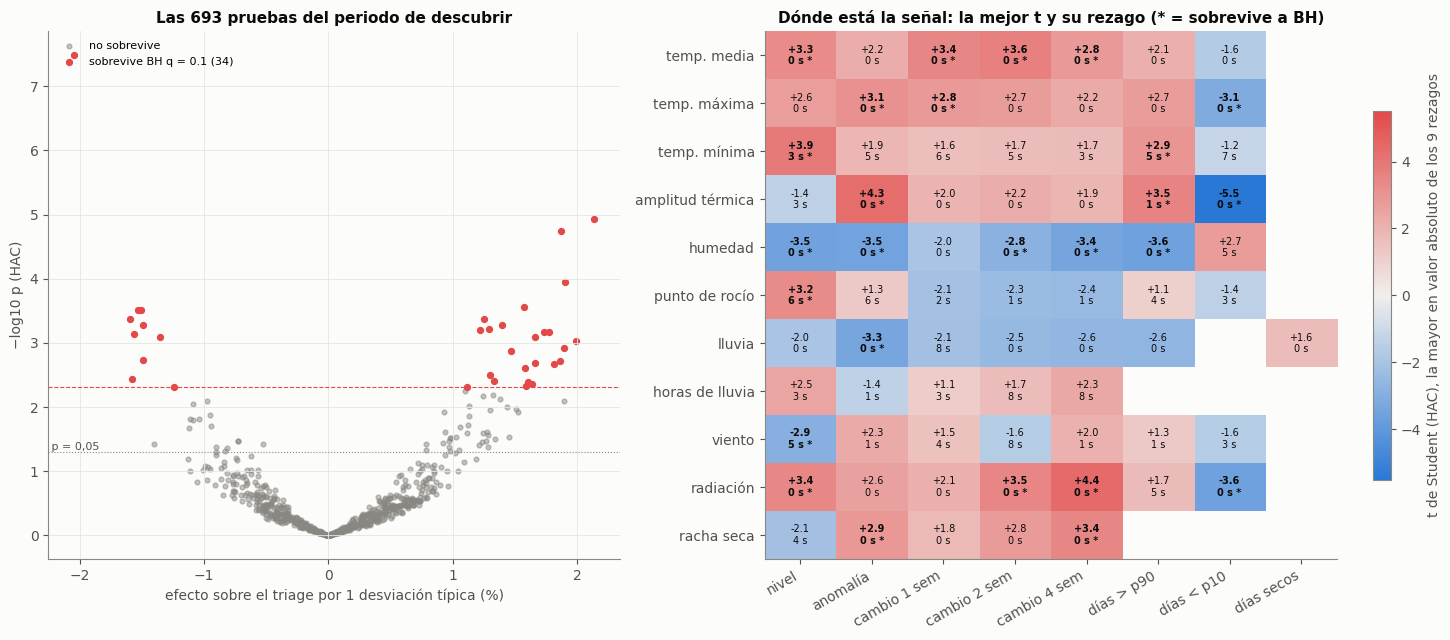

,0 sem,1 sem,2 sem,3 sem,4 sem,5 sem,6 sem,7 sem,8 sem
temporada: t por rezago,,,,,,,,,
giro 4 sem (pp),-1.4,0.3,-0.2,-0.6,-0.3,-0.9,0.1,1.6,1.2
giro 8 sem (pp),-0.6,-0.5,-0.0,0.5,0.7,0.6,0.8,0.6,0.4
lluvia 4 sem (% sobre lo normal),-2.3,-0.6,-0.5,-0.3,-0.1,-0.9,-0.3,0.4,0.2
lluvia 8 sem (% sobre lo normal),-1.8,-1.7,-0.8,-0.5,-0.3,-0.5,-0.5,-0.5,-0.6


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
umbral = B.loc[B["sobrevive BH"], "p"].max() if B["sobrevive BH"].any() else B.p.min() / 2
ax.scatter(B["efecto %"], -np.log10(B.p), s=12, color=MUDO, alpha=.5, label="no sobrevive")
ax.scatter(S["efecto %"], -np.log10(S.p), s=18, color=ROJO, label=f"sobrevive BH q = {Q_BH} ({len(S)})")
ax.axhline(-np.log10(umbral), color=ROJO, lw=.8, ls="--"); ax.axhline(-np.log10(.05), color=MUDO, lw=.8, ls=":")
ax.text(ax.get_xlim()[0], -np.log10(.05), " p = 0,05", va="bottom", fontsize=8, color=TINTA2)
ax.set_xlabel("efecto sobre el triage por 1 desviación típica (%)"); ax.set_ylabel("−log10 p (HAC)")
ax.set_title(f"Las {B.p.notna().sum()} pruebas del periodo de descubrir"); ax.legend(fontsize=8, loc="upper left")
# mapa: la mejor t de cada variable x forma (con signo) y su rezago
B["t"] = B.b / B.se
mejor = B.loc[B.groupby(["variable", "forma"]).t.apply(lambda s: s.abs().idxmax() if s.notna().any() else s.index[0])]
formas = ["nivel", "anomalía", "cambio 1 sem", "cambio 2 sem", "cambio 4 sem", "días > p90", "días < p10", "días secos"]
M = mejor.pivot(index="variable", columns="forma", values="t").reindex(columns=[f for f in formas if f in mejor.forma.values])
R = mejor.pivot(index="variable", columns="forma", values="rezago").reindex_like(M)
M = M.reindex([v for v in nivel.columns if v in M.index])
R = R.reindex(M.index)
ax = axes[1]; lim = np.nanmax(np.abs(M.values))
im = ax.imshow(M.values, cmap=DIVERGENTE, vmin=-lim, vmax=lim, aspect="auto")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        if np.isfinite(M.values[i, j]):
            ok = ((S.variable == M.index[i]) & (S.forma == M.columns[j])).any()
            ax.text(j, i, f"{M.values[i, j]:+.1f}\n{int(R.values[i, j])} s" + (" *" if ok else ""), ha="center", va="center", fontsize=7,
                    color=TINTA, fontweight="bold" if ok else "normal")
ax.set_xticks(range(M.shape[1]), M.columns, rotation=30, ha="right"); ax.set_yticks(range(M.shape[0]), M.index); ax.grid(False)
plt.colorbar(im, ax=ax, shrink=.7, label="t de Student (HAC), la mayor en valor absoluto de los 9 rezagos")
ax.set_title("Dónde está la señal: la mejor t y su rezago (* = sobrevive a BH)")
plt.tight_layout(); plt.show()
tt = B[B.variable.eq("temporada")].pivot(index="forma", columns="rezago", values="t").round(1)
tt.columns = [f"{k} sem" for k in tt.columns]; tt.index.name = "temporada: t por rezago"
tt

**En descubrir hay más pruebas con p < 0,05 de las que da la cuenta del 5 %, pero la señal es pequeña y casi toda es de la
misma semana.**
- 84 de las 693 pruebas dan p < 0,05 (la cuenta ingenua daría ~35).
- 34 sobreviven a BH, que son 26 variables derivadas de 10 variables base.
- **22 de las 34 están a rezago 0.** Solo 12 miran hacia atrás (1 a 8 semanas).

El patrón es uno solo visto desde muchas variables: **las semanas soleadas, secas y cálidas traen algo más de triage**. Las
mayores:

| Variable | Rezago | Efecto por 1 sd | IC95 |
|---|---|---|---|
| Amplitud térmica, días < p10 (días nublados y parejos) | 0 | **−2,0 %** | [−2,8; −1,3] |
| Radiación, cambio a 4 semanas | 0 | **+2,1 %** | [+1,2; +3,1] |
| Amplitud térmica, anomalía | 0 | +1,9 % | [+1,0; +2,7] |
| Temperatura mínima, nivel | 3 | +1,9 % | [+0,9; +2,9] |
| Humedad, nivel | 0 | −1,6 % | [−2,5; −0,7] |
| Lluvia, anomalía | 0 | −1,4 % | [−2,1; −0,6] |

El tamaño es de 1 a 2 % por desviación típica, frente a un ruido semanal del desenlace del 6 %. Está en el extremo bajo del
rango que publica la literatura (2 a 10 %).

**La temporada no aparece.** Ninguna de las cuatro variables de temporada sobrevive: la lluvia de 4 semanas llega a t = −2,3 a
rezago 0; la de 8 semanas, a −1,8 a rezago 0; el giro de 4 semanas, a +1,6 a 7 semanas, y el giro de 8 semanas no pasa de 0,8.
En 2022-2024, el paso de seco a lluvioso a escala de temporada no se siguió de más triage total.

**Límites.** Las variables están muy correlacionadas entre sí: la radiación, la amplitud, la humedad y la lluvia miden el mismo
estado del cielo, de modo que 34 supervivientes no son 34 hallazgos. El rezago 0 no sirve para anticipar sin un pronóstico del
tiempo de esa misma semana. Y el desenlace conserva la estación, así que una variable de nivel puede estar haciendo de reloj del
año. Cuántos de esos «hallazgos» produce el azar con esta misma estructura se mide en la sección 3.1.

## 3.1 Cómo se mide lo que el azar da por sí solo

Contar los «hallazgos» frente al 5 % de las pruebas supone pruebas independientes, y aquí no lo son: las variables de clima
comparten el mismo estado del cielo y el desenlace tiene memoria. Para saber cuántos hallazgos produce el azar con esta
estructura se repite el barrido completo **300 veces con el desenlace desplazado en círculo** una cantidad aleatoria de
semanas. El desplazamiento conserva la autocorrelación del desenlace y la estructura del clima, y rompe solo la relación
entre ambos. De cada repetición se anota cuántas pruebas dan p < 0,05, cuántas sobreviven a BH y cuántas se confirmarían en el
segundo periodo, también desplazado. La regresión se reimplementa en una función rápida que se comprueba contra `statsmodels`
(misma pendiente, mismo error HAC y mismo p) para poder repetirla cientos de veces.

In [8]:
# ---- Ajuste rápido de una regresión simple con errores HAC (Bartlett, 4 rezagos) y efectos fijos opcionales.
# Es la misma cuenta que sm.OLS(...).fit(cov_type="HAC"), unas 50 veces más rápida, y permite repetir el barrido
# completo cientos de veces con el desenlace desplazado al azar (la prueba de lo que el azar da por sí solo).
def _sin_grupo(v, g, k):
    return v - (np.bincount(g, v, k) / np.maximum(np.bincount(g, minlength=k), 1))[g]

def ajuste_rapido(y, x, mes=None, L=4):
    ok = np.isfinite(y) & np.isfinite(x)
    if ok.sum() < 30: return np.nan, np.nan
    yy, xx = y[ok], x[ok]
    if mes is None: yy, xx = yy - yy.mean(), xx - xx.mean()
    else: g = mes[ok]; yy, xx = _sin_grupo(yy, g, 12), _sin_grupo(xx, g, 12)
    sxx = xx @ xx
    if sxx <= 1e-12: return np.nan, np.nan
    b = (xx @ yy) / sxx
    u = xx * (yy - b * xx)
    s = u @ u
    for j in range(1, L + 1): s += 2 * (1 - j / (L + 1)) * (u[j:] @ u[:-j])
    return b, np.sqrt(max(s, 0)) / sxx

def ajuste_con_Z(y, x, Z, L=4):
    """Lo mismo con efectos fijos arbitrarios (Z: indicadoras de mes y de año)."""
    ok = np.isfinite(y) & np.isfinite(x)
    if ok.sum() < 30: return np.nan, np.nan
    Zc = Z[ok]; Zc = np.column_stack([np.ones(len(Zc)), Zc[:, Zc.any(axis=0)]])
    R = np.column_stack([y[ok], x[ok]])
    R = R - Zc @ np.linalg.lstsq(Zc, R, rcond=None)[0]
    yy, xx = R[:, 0], R[:, 1]
    sxx = xx @ xx
    if sxx <= 1e-12: return np.nan, np.nan
    b = (xx @ yy) / sxx
    u = xx * (yy - b * xx)
    s = u @ u
    for j in range(1, L + 1): s += 2 * (1 - j / (L + 1)) * (u[j:] @ u[:-j])
    return b, np.sqrt(max(s, 0)) / sxx

def pval(b, se):
    with np.errstate(all="ignore"): p = 2 * norm.sf(np.abs(b / se))
    return np.where(np.isfinite(p), p, 1.0)

def bh(p, q=Q_BH): return multipletests(p, alpha=q, method="fdr_bh")[0]

def _ajustador(idx, fijo):
    if fijo is None: return lambda y, x: ajuste_rapido(y, x, None)
    m = (idx + pd.Timedelta(days=3)).month.values - 1
    if fijo == "mes": return lambda y, x: ajuste_rapido(y, x, m)
    Z = np.column_stack([pd.get_dummies(pd.Index(m), drop_first=True).values.astype(float),
                         pd.get_dummies(pd.Index((idx + pd.Timedelta(days=3)).year), drop_first=True).values.astype(float)])
    return lambda y, x: ajuste_con_Z(y, x, Z)

def evaluar(y, X, rezagos, desc, conf, fijo="mes", n_sim=N_SIM, semilla=0):
    """Barre todas las columnas de X a cada rezago en descubrir y en confirmar, y repite el barrido n_sim veces con el
    desenlace desplazado en círculo (conserva su autocorrelación y deja intacta la estructura del clima): eso da lo que
    el azar produce por sí solo en el número de pruebas con p < 0,05, en las que sobreviven a BH y en las que se confirman."""
    cols = [(c, k) for c in X.columns for k in rezagos]
    def armar(per):
        idx = y.loc[per[0]:per[1]].index
        XL = np.vstack([X[c].shift(k).reindex(idx).values.astype(float) for c, k in cols])
        return y.reindex(idx).values.astype(float), XL, _ajustador(idx, fijo)
    yd, XLd, fd = armar(desc); yc, XLc, fc = armar(conf)
    def tabla(yv, XL, f):
        r = np.array([f(yv, x) for x in XL]); return r[:, 0], r[:, 1]
    def estadisticos(bd, sd, bc, sc):
        pd_, pc_ = pval(bd, sd), pval(bc, sc); sob = bh(pd_)
        conf_ = sob & (np.sign(bd) == np.sign(bc)) & (pc_ < .05)
        td, tc = bd / sd, bc / sc; ok = np.isfinite(td) & np.isfinite(tc)
        return dict(p05=int((pd_ < .05).sum()), bh=int(sob.sum()), conf=int(conf_.sum()), rtt=float(np.corrcoef(td[ok], tc[ok])[0, 1]), p05c=int((pc_ < .05).sum()))
    bd, sd = tabla(yd, XLd, fd); bc, sc = tabla(yc, XLc, fc)
    obs = estadisticos(bd, sd, bc, sc)
    rng = np.random.default_rng(semilla)
    nulo = []
    for _ in range(n_sim):
        s1, s2 = rng.integers(8, len(yd) - 8), rng.integers(8, len(yc) - 8)
        b1, e1 = tabla(np.roll(yd, s1), XLd, fd); b2, e2 = tabla(np.roll(yc, s2), XLc, fc)
        nulo.append(estadisticos(b1, e1, b2, e2))
    nulo = pd.DataFrame(nulo)
    T = pd.DataFrame({"variable": [c[0][0] if isinstance(c[0], tuple) else c[0] for c in cols],
                      "forma": [c[0][1] if isinstance(c[0], tuple) else "índice" for c in cols],
                      "rezago": [c[1] for c in cols], "b": bd, "se": sd, "p": pval(bd, sd), "b_conf": bc, "se_conf": sc, "p_conf": pval(bc, sc)})
    T["efecto %"], T["efecto % conf"] = pct(T.b), pct(T.b_conf)
    T["t"], T["t_conf"] = T.b / T.se, T.b_conf / T.se_conf
    T["q"] = multipletests(T.p, method="fdr_bh")[1]
    T["sobrevive"] = bh(T.p.values)
    T["confirma"] = T.sobrevive & (np.sign(T.b) == np.sign(T.b_conf)) & (T.p_conf < .05)
    emp = lambda k: (1 + int((nulo[k] >= obs[k]).sum())) / (n_sim + 1)
    resumen = {"pruebas": len(T), "p<0,05": obs["p05"], "azar (media)": nulo.p05.mean(), "azar (p95)": nulo.p05.quantile(.95), "p emp. p<0,05": emp("p05"),
               "sobreviven BH": obs["bh"], "BH azar (media)": nulo.bh.mean(), "BH azar (p95)": nulo.bh.quantile(.95), "p emp. BH": emp("bh"),
               "se confirman": obs["conf"], "conf. azar (media)": nulo.conf.mean(), "conf. azar (p95)": nulo.conf.quantile(.95), "p emp. conf.": emp("conf"),
               "r(t desc., t conf.)": obs["rtt"], "r azar (media)": nulo.rtt.mean(), "r azar (p95)": nulo.rtt.quantile(.95), "p emp. r": emp("rtt"), "p emp. r (inversión)": (1 + int((nulo["rtt"] <= obs["rtt"]).sum())) / (n_sim + 1)}
    return {"T": T, "resumen": resumen, "nulo": nulo, "obs": obs}

def tabla_resumen(EV, claves):
    return pd.DataFrame({k: {c: EV[k]["resumen"][c] for c in claves} for k in EV}).T

In [9]:
# comprobación del ajuste rápido contra statsmodels (misma pendiente, mismo error HAC, mismo p)
filas = []
yv = Y.y.loc[DESC[0]:DESC[1]]
mes_d = pd.get_dummies(pd.Series((yv.index + pd.Timedelta(days=3)).month, index=yv.index), prefix="m", drop_first=True).astype(float)
for c in [("radiación", "cambio 2 sem"), ("humedad", "nivel"), ("temporada", "giro 4 sem (pp)"), ("amplitud térmica", "días < p10")]:
    for k in (0, 3):
        x = Xs[c].shift(k).reindex(yv.index)
        for etiqueta, extra in [("sin mes", None), ("con mes", mes_d)]:
            r = prueba(yv, x, extra)
            m = (yv.index + pd.Timedelta(days=3)).month.values - 1 if extra is not None else None
            b, se = ajuste_rapido(yv.values.astype(float), x.values.astype(float), m)
            filas.append({"variable": c[0] + ", " + c[1], "rezago": k, "ajuste": etiqueta, "dif. pendiente": abs(r["b"] - b), "dif. error": abs(r["se"] - se), "dif. p": abs(r["p"] - pval(b, se)[()])})
comp = pd.DataFrame(filas)
print("diferencia máxima con statsmodels: pendiente {:.1e}, error típico {:.1e}, p {:.1e}".format(comp["dif. pendiente"].max(), comp["dif. error"].max(), comp["dif. p"].max()))

diferencia máxima con statsmodels: pendiente 2.6e-15, error típico 7.5e-15, p 3.1e-13


[55 s]


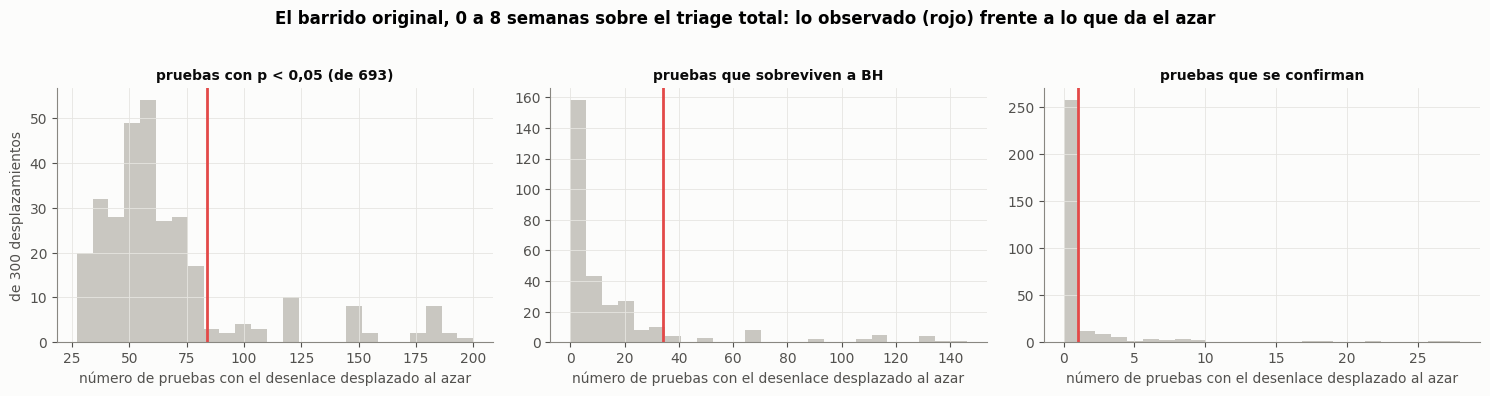

,"triage total, 0 a 8 semanas"
pruebas,693.000
"p<0,05",84.000
azar (media),66.670
azar (p95),149.400
"p emp. p<0,05",0.153
sobreviven BH,34.000
BH azar (media),15.520
BH azar (p95),69.050
p emp. BH,0.123
se confirman,1.000


In [10]:
t0 = time.time()
EVA = evaluar(Y.y, Xs, range(0, 9), DESC, CONF, fijo=None, n_sim=N_SIM, semilla=0)
print(f"[{time.time()-t0:.0f} s]")
cl_ = ["pruebas", "p<0,05", "azar (media)", "azar (p95)", "p emp. p<0,05", "sobreviven BH", "BH azar (media)", "BH azar (p95)", "p emp. BH", "se confirman", "conf. azar (media)", "conf. azar (p95)", "p emp. conf.", "r(t desc., t conf.)", "r azar (media)", "r azar (p95)", "p emp. r"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (col, tit) in zip(axes, [("p05", "pruebas con p < 0,05 (de 693)"), ("bh", "pruebas que sobreviven a BH"), ("conf", "pruebas que se confirman")]):
    ax.hist(EVA["nulo"][col], bins=25, color="#c9c7c1"); ax.axvline(EVA["obs"][col], color=ROJO, lw=2)
    ax.set_title(tit, fontsize=10); ax.set_xlabel("número de pruebas con el desenlace desplazado al azar")
axes[0].set_ylabel("de 300 desplazamientos")
fig.suptitle("El barrido original, 0 a 8 semanas sobre el triage total: lo observado (rojo) frente a lo que da el azar", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()
pd.Series({c: EVA["resumen"][c] for c in cl_}, name="triage total, 0 a 8 semanas").round(3).to_frame()

**La cuenta del 5 % subestimaba el azar.** Con el desenlace desplazado al azar, el barrido de 693 pruebas da en promedio
**66,7 pruebas con p < 0,05** (percentil 95: 149,4), no 35, y **15,5 supervivientes a BH** (percentil 95: 69,1). Lo observado
(84 y 34) queda dentro de esa distribución: el p empírico es 0,15 para las pruebas con p < 0,05 y 0,12 para las que sobreviven a BH.
La causa es la estructura: las 77 variables son en buena parte la misma señal y el desenlace es persistente, de modo que cuando
una prueba sale «significativa» por azar arrastra a decenas de vecinas.

La confirmación dice lo mismo. El azar da en promedio 1,05 confirmaciones (percentil 95: 5,05); se observó 1 (p empírico 0,31). Y la
correlación entre el t de descubrir y el t de confirmar a lo largo de las 693 pruebas es −0,006, con el percentil 95 del azar
en 0,29: lo que apareció en 2022-2024 no se parece, como patrón, a lo de 2025-2026.

**Lo que esto cambia.** Antes se leía «84 contra ~35 esperadas: hay señal por encima del azar». Con el azar bien medido, el
resultado del barrido original es **compatible con ausencia de relación**. No prueba que no la haya: dice que ese diseño no puede
distinguir la señal del ruido.

## 3.2 Confirmación en 2025-2026 del barrido original

Cada una de las 34 pruebas supervivientes se repite con la misma variable, la misma forma y el mismo rezago en 2025-01 a
2026-08, con la escala de descubrir. El criterio es el mismo signo y p < 0,05. Para no confundir «no se repite» con «no hay
datos para verlo» se calcula la potencia: la probabilidad de confirmar si el efecto real fuera el de descubrir.

In [11]:
CF = pd.DataFrame([prueba(Y.y.loc[CONF[0]:CONF[1]], Xs[(r.variable, r.forma)].shift(r.rezago)) for r in S.itertuples()], index=S.index)
S = S.join(CF.add_suffix(" conf"))
S["efecto % conf"] = pct(S["b conf"])
S["mismo signo"] = np.sign(S.b) == np.sign(S["b conf"])
S["confirma (mismo signo, p < 0,05)"] = S["mismo signo"] & (S["p conf"] < .05)
from scipy.stats import norm
S["potencia"] = norm.cdf(S.b.abs() / S["se conf"] - 1.96)   # si el efecto real fuera el de descubrir
if len(S):
    S["confirma BH"] = multipletests(np.where(S["mismo signo"], S["p conf"] / 2, 1), alpha=Q_BH, method="fdr_bh")[0]  # unilateral en la dirección descubierta
print(f"sobreviven a BH en descubrir: {len(S)}; mismo signo en confirmar: {int(S['mismo signo'].sum())}; "
      f"confirman con p < 0,05: {int(S['confirma (mismo signo, p < 0,05)'].sum())}; confirman con BH unilateral q = {Q_BH} en la familia de confirmación: "
      f"{int(S['confirma BH'].sum()) if len(S) else 0}")
print(f"error típico mediano: descubrir {100 * S.se.median():.2f} pp, confirmar {100 * S['se conf'].median():.2f} pp; potencia mediana para "
      f"repetir el efecto descubierto: {S.potencia.median():.2f} -> se esperarían ~{S.potencia.sum():.0f} confirmaciones si todo fuera real "
      f"(sin descontar la maldición del ganador)")
print(f"si NADA fuera real, cada prueba confirma por azar con probabilidad 0,025 (mismo signo y p < 0,05): se esperarían {0.025 * len(S):.2f} de {len(S)}")
print(f"efecto en confirmar / efecto en descubrir, mediana: {(S['efecto % conf'] / S['efecto %']).median():.2f}")
print(f"días con pluviómetro válido: descubrir {100 * v.loc['2022-03-06':'2024-12-28'].mean():.1f} %, confirmar {100 * v.loc['2025-01-05':'2026-08-28'].mean():.1f} %")
C = S[S["confirma (mismo signo, p < 0,05)"]].copy()
# diagnóstico, no una prueba nueva: ¿el efecto confirmado sigue con el mes del año fijo? (¿clima o estación?)
todo = (DESC[0], CONF[1])
mes_d = pd.get_dummies(pd.Series(((Y.index + pd.Timedelta(days=3)).month), index=Y.index), prefix="m", drop_first=True).astype(float)
C["efecto % con mes fijo 2022-26"] = [pct(prueba(Y.y.loc[todo[0]:todo[1]], Xs[(r.variable, r.forma)].shift(r.rezago), mes_d)["b"]) for r in C.itertuples()]
C["p con mes fijo"] = [prueba(Y.y.loc[todo[0]:todo[1]], Xs[(r.variable, r.forma)].shift(r.rezago), mes_d)["p"] for r in C.itertuples()]
S[["variable", "forma", "rezago", "efecto %", "p", "efecto % conf", "p conf", "potencia", "mismo signo", "confirma (mismo signo, p < 0,05)"]] \
  .sort_values(["confirma (mismo signo, p < 0,05)", "p conf"], ascending=[False, True]).round({"efecto %": 1, "efecto % conf": 1, "p": 5, "p conf": 4, "potencia": 2})

sobreviven a BH en descubrir: 34; mismo signo en confirmar: 18; confirman con p < 0,05: 1; confirman con BH unilateral q = 0.1 en la familia de confirmación: 0
error típico mediano: descubrir 0.46 pp, confirmar 0.83 pp; potencia mediana para repetir el efecto descubierto: 0.49 -> se esperarían ~18 confirmaciones si todo fuera real (sin descontar la maldición del ganador)
si NADA fuera real, cada prueba confirma por azar con probabilidad 0,025 (mismo signo y p < 0,05): se esperarían 0.85 de 34
efecto en confirmar / efecto en descubrir, mediana: 0.04
días con pluviómetro válido: descubrir 35.8 %, confirmar 53.2 %


,variable,forma,rezago,efecto %,p,efecto % conf,p conf,potencia,mismo signo,"confirma (mismo signo, p < 0,05)"
432,radiación,cambio 2 sem,0,1.4,0.00053,1.2,0.0365,0.68,True,True
536,temp. mínima,días > p90,5,1.3,0.00322,-2.3,0.0184,0.25,False,False
550,amplitud térmica,días > p90,1,1.3,0.00042,-1.0,0.1552,0.46,False,False
486,racha seca,cambio 4 sem,0,1.2,0.00063,1.3,0.2155,0.21,True,False
459,racha seca,anomalía,0,1.3,0.00393,0.4,0.3026,0.96,True,False
93,temp. mínima,nivel,3,1.9,0.00011,1.0,0.3116,0.50,True,False
92,temp. mínima,nivel,2,1.7,0.00209,0.8,0.3474,0.49,True,False
231,punto de rocío,nivel,6,1.9,0.00118,0.7,0.3516,0.71,True,False
36,temp. media,cambio 4 sem,0,1.6,0.00468,-0.5,0.3625,0.79,False,False
216,humedad,cambio 4 sem,0,-1.6,0.00074,0.7,0.3630,0.55,False,False


,variable,forma,rezago,efecto %,efecto % conf,p conf,efecto % con mes fijo 2022-26,p con mes fijo
432,radiación,cambio 2 sem,0,1.4,1.2,0.0365,1.0,0.001


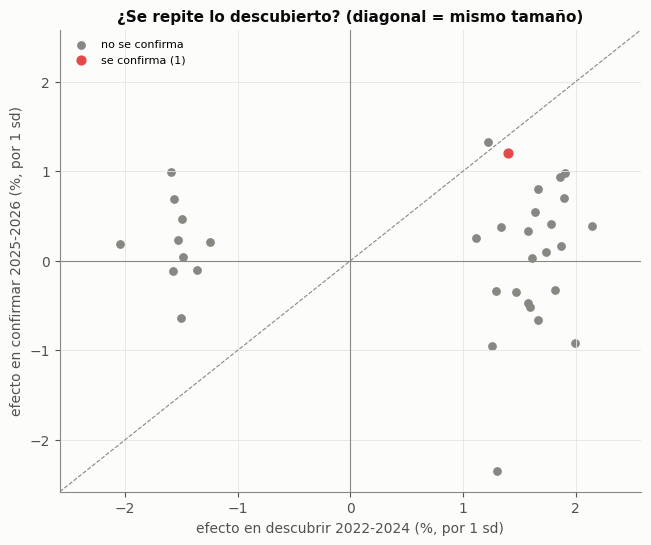

In [12]:
display(C[["variable", "forma", "rezago", "efecto %", "efecto % conf", "p conf", "efecto % con mes fijo 2022-26", "p con mes fijo"]]
        .round({"efecto %": 1, "efecto % conf": 1, "p conf": 4, "efecto % con mes fijo 2022-26": 1, "p con mes fijo": 4}))
fig, ax = plt.subplots(figsize=(7.5, 6))
nc = ~S["confirma (mismo signo, p < 0,05)"]
ax.scatter(S.loc[nc, "efecto %"], S.loc[nc, "efecto % conf"], s=28, color=MUDO, label="no se confirma")
ax.scatter(C["efecto %"], C["efecto % conf"], s=40, color=ROJO, label=f"se confirma ({len(C)})")
lim = np.nanmax(np.abs(S[["efecto %", "efecto % conf"]].values)) * 1.1 if len(S) else 5
ax.plot([-lim, lim], [-lim, lim], color=MUDO, lw=.8, ls="--"); ax.axhline(0, color=MUDO, lw=.8); ax.axvline(0, color=MUDO, lw=.8)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel("efecto en descubrir 2022-2024 (%, por 1 sd)"); ax.set_ylabel("efecto en confirmar 2025-2026 (%, por 1 sd)")
ax.set_title("¿Se repite lo descubierto? (diagonal = mismo tamaño)"); ax.legend(fontsize=8); plt.show()

**Casi nada se confirma, y lo que se confirma es lo que daría el azar.**

| | |
|---|---|
| Sobreviven a BH en descubrir | 34 |
| Mismo signo en confirmar | 18 (la mitad) |
| **Confirman (mismo signo, p < 0,05)** | **1** |
| Confirman con BH en la familia de confirmación | **0** |
| Confirmaciones esperadas si **todo** fuera real | ~18 (potencia mediana 0,49) |
| Confirmaciones esperadas si **nada** fuera real, con la cuenta ingenua | 0,85 |
| Confirmaciones que da el azar con la estructura real (sección 3.1) | 1,05 |

- El efecto en confirmar es, en mediana, el 4 % del de descubrir.
- No es escasez de datos: con la potencia calculada, un efecto real del tamaño descubierto se habría repetido la mitad de las veces. Y
  tampoco es peor medida: en confirmar hay más días con pluviómetro válido (53,2 %) que en descubrir (35,8 %).
- Una prueba **se invierte con significación**: los días con mínima > p90, a 5 semanas, pasan de +1,3 % a −2,3 % (p = 0,018).

**La única que se repite es el cambio de radiación a 2 semanas, a rezago 0.** Una semana más soleada que la de hace dos semanas
trae +1,4 % de triage en descubrir y +1,2 % en confirmar (p = 0,037), y +1,0 % con el mes del año fijo en 2022-2026 (p = 0,001).
Pero una confirmación entre 34 es lo que da el azar, y es contemporánea: se lee mejor como acceso (el cielo despejado saca a la
gente de casa) que como contagio, que tendría rezago. Es un candidato, no un hallazgo.

---
# 4. El barrido con el reloj del mecanismo: rezagos de 1 a 5 semanas y bandas de edad

Se cambian tres cosas respecto del barrido original:

- **Rezagos de 1 a 5 semanas.** Un contagio necesita días de incubación y de decisión de consultar; una variable de la misma
  semana queda fuera de la familia. Son 77 variables × 5 rezagos = 385 pruebas por desenlace.
- **Efectos fijos de mes y de año.** El desenlace conserva la estación, así que una variable de nivel puede estar haciendo de
  reloj del año; y el nivel de cada año depende de la red de salud. Con mes y año fijos, lo que se mide es lo que el clima
  añade a lo habitual de ese mes en ese año. La sección 4.4 muestra cuánto depende el resultado de este control.
- **Subgrupos.** Cada banda de edad se trata como el total (sin calendario, sin nivel del año, sin escalones de la red). Las
  cinco bandas suman el total día a día.

## 4.1 Las bandas de edad

In [13]:
# ---- El triage por banda de edad, tratado igual que el total: sin calendario, sin nivel del año, sin escalones de la red
dias = pd.date_range("2020-01-01", "2026-09-19")
ed = pd.read_parquet(RAIZ / "salidas/triage_edad.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
E = ed.pivot_table(index="dia", columns="banda", values="n", aggfunc="sum").reindex(dias).fillna(0)
tri = pd.read_parquet(RAIZ / "salidas/triage_diario.parquet").assign(dia=lambda d: pd.to_datetime(d.dia)).set_index("dia")["triages"].reindex(dias).astype(float)
tri["2024-03-19":"2024-03-21"] = np.nan                  # caída del registro
E[tri.isna()] = np.nan
completas = de._semana(tri.notna().astype(int)) == 7
cal = (pd.read_csv(RAIZ / "calendarios/calendario_Colombia.csv", parse_dates=["fecha"]).set_index("fecha")
         .reindex(dias)[de.CAL].apply(pd.to_numeric, errors="coerce").fillna(0))
cal_w = de._semana(cal).loc[de.INICIO:de.FIN]
SEMANAL_EDAD = {b: de._semana(E[b]).where(completas).loc[de.INICIO:de.FIN] for b in BANDAS}
RB = pd.DataFrame({b: de._residuo(s, cal_w) for b, s in SEMANAL_EDAD.items()})
dif = (E.sum(axis=1) - tri).abs().max()
print(f"las cinco bandas suman el total diario (diferencia máxima {dif:.0f} triages)")
peso = pd.DataFrame({"triages por semana (2022-03 a 2024-12)": {BANDAS[b]: SEMANAL_EDAD[b].loc[DESC[0]:DESC[1]].mean() for b in BANDAS},
                     "% del triage": {BANDAS[b]: 100 * SEMANAL_EDAD[b].loc[DESC[0]:DESC[1]].mean() / Y.triage.loc[DESC[0]:DESC[1]].mean() for b in BANDAS},
                     "desviación típica semanal del residuo (%)": {BANDAS[b]: 100 * RB[b].loc[DESC[0]:DESC[1]].std() for b in BANDAS}})
peso.loc["total"] = [Y.triage.loc[DESC[0]:DESC[1]].mean(), 100.0, 100 * Y.y.loc[DESC[0]:DESC[1]].std()]
print("correlación del residuo de cada banda con el del total:", {BANDAS[b]: round(RB[b].corr(Y.y), 2) for b in BANDAS})
peso.round(1)

las cinco bandas suman el total diario (diferencia máxima 0 triages)
correlación del residuo de cada banda con el del total: {'0 a 4 años': 0.46, '5 a 14 años': 0.42, '15 a 44 años': 0.86, '45 a 64 años': 0.66, '65 años y más': 0.58}


,triages por semana (2022-03 a 2024-12),% del triage,desviación típica semanal del residuo (%)
0 a 4 años,43.2,3.0,26.1
5 a 14 años,64.4,4.5,23.0
15 a 44 años,787.7,55.1,6.6
45 a 64 años,263.5,18.4,8.5
65 años y más,269.1,18.8,9.1
total,1429.7,100.0,6.1


**El total es, en la práctica, el triage de los adultos de 15 a 44 años.** Ese grupo es el 55,1 % de las solicitudes y su
residuo correlaciona 0,86 con el del total; las otras bandas correlacionan entre 0,42 y 0,66. Las bandas pediátricas pesan poco
(3,0 % y 4,5 %) y son muy ruidosas: su residuo semanal varía 26,1 % y 23,0 %, contra 6,1 % del total. Es el costo de mirar las
partes: un efecto potencialmente mayor, pero sobre una serie de 43 a 64 triages por semana.

## 4.2 El barrido por banda, con el azar medido

In [14]:
SALIDAS = {"triage total": Y.y, **{f"edad {BANDAS[b]}": RB[b] for b in BANDAS}, "egresos respiratorios": Y.y_respiratorio}
EV = {}
for nombre, s in SALIDAS.items():
    EV[nombre] = evaluar(s, Xs, REZ_MEC, DESC, CONF, fijo="mes+año", n_sim=N_SIM, semilla=1)
claves = ["pruebas", "p<0,05", "azar (media)", "azar (p95)", "p emp. p<0,05", "sobreviven BH", "BH azar (media)", "BH azar (p95)", "p emp. BH",
          "se confirman", "conf. azar (media)", "conf. azar (p95)", "p emp. conf.", "r(t desc., t conf.)", "r azar (media)", "r azar (p95)", "p emp. r"]
print(tabla_resumen(EV, claves).round(3).T.to_string())

                     triage total  edad 0 a 4 años  edad 5 a 14 años  edad 15 a 44 años  edad 45 a 64 años  edad 65 años y más  egresos respiratorios
pruebas                   385.000          385.000           385.000            385.000            385.000             385.000                385.000
p<0,05                     31.000           56.000            84.000             59.000             66.000              29.000                 12.000
azar (media)               34.940           43.993            47.610             33.200             41.090              47.280                 36.533
azar (p95)                 74.250           76.000           109.000             69.000             81.000              89.000                 82.000
p emp. p<0,05               0.495            0.193             0.123              0.156              0.156               0.728                  0.887
sobreviven BH               6.000           17.000            58.000             25.000             

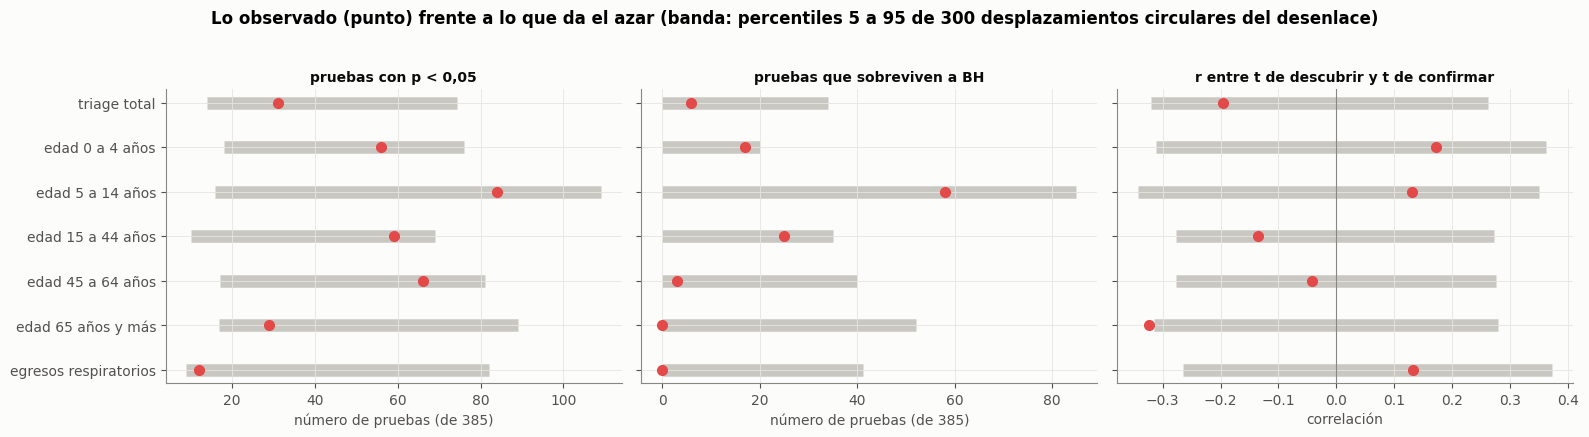

In [15]:
nombres = list(EV)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (obs, medio, p95, tit) in zip(axes, [("p<0,05", "azar (media)", "azar (p95)", "pruebas con p < 0,05"),
                                           ("sobreviven BH", "BH azar (media)", "BH azar (p95)", "pruebas que sobreviven a BH"),
                                           ("r(t desc., t conf.)", "r azar (media)", "r azar (p95)", "r entre t de descubrir y t de confirmar")]):
    y_ = np.arange(len(nombres))[::-1]
    for yy, n in zip(y_, nombres):
        r = EV[n]["resumen"]; nul = EV[n]["nulo"]
        col = {"p<0,05": "p05", "sobreviven BH": "bh", "r(t desc., t conf.)": "rtt"}[obs]
        ax.hlines(yy, nul[col].quantile(.05), nul[col].quantile(.95), color="#c9c7c1", lw=9, zorder=1)
        ax.plot(r[obs], yy, "o", color=ROJO, ms=7, zorder=3)
    ax.set_yticks(y_, nombres if ax is axes[0] else [""] * len(nombres)); ax.set_title(tit, fontsize=10)
    if obs.startswith("r("): ax.axvline(0, color=MUDO, lw=.8)
axes[0].set_xlabel("número de pruebas (de 385)"); axes[1].set_xlabel("número de pruebas (de 385)"); axes[2].set_xlabel("correlación")
fig.suptitle("Lo observado (punto) frente a lo que da el azar (banda: percentiles 5 a 95 de 300 desplazamientos circulares del desenlace)", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

**Ninguno de los siete desenlaces supera al azar a un nivel convencional, y tres bandas se acercan.**

| Desenlace | Sobreviven a BH | Azar: media (p95) | p empírico | Se confirman | Azar: media |
|---|---|---|---|---|---|
| Triage total | 6 | 7,3 (34,1) | 0,33 | 0 | 0,53 |
| 0 a 4 años | 17 | 5,3 (20,0) | 0,08 | 1 | 0,52 |
| 5 a 14 años | 58 | 14,3 (85,0) | 0,08 | 2 | 1,28 |
| 15 a 44 años | 25 | 6,5 (35,0) | 0,09 | 0 | 0,33 |
| 45 a 64 años | 3 | 9,0 (40,0) | 0,52 | 0 | 0,60 |
| 65 años y más | 0 | 14,0 (52,1) | 1,00 | 0 | 0,81 |
| Egresos respiratorios | 0 | 6,3 (41,2) | 1,00 | 0 | 0,68 |

- **Las bandas de 0 a 4, 5 a 14 y 15 a 44 años son las que más se acercan al límite del azar**, con p empírico entre 0,08 y 0,09 en el
  número de supervivientes. En el total no se ve nada, y es lo esperable si los efectos de las partes tienen signos distintos
  y se cancelan en la suma.
- **En confirmar no se sostienen.** Se confirman 1 prueba en 0 a 4 años y 2 en 5 a 14, y la correlación del patrón entre
  periodos queda dentro de lo que da el azar (+0,17; +0,13; −0,14), con los puntos de la figura dentro de la banda gris.
- Cuando el número de supervivientes de una banda es alto, el azar también da mucho: en 5 a 14 años el percentil 95 del azar es
  85 supervivientes, porque esa serie es ruidosa y persistente y sus pruebas son casi la misma prueba repetida.

La figura resume la comparación de las tres medidas: el punto rojo es lo observado y la banda gris, el rango que da el azar. Un
hallazgo real tendría que quedar claramente a la derecha de la banda. Ninguno lo hace en el número de pruebas con p < 0,05, y
solo 0 a 4, 5 a 14 y 15 a 44 años se acercan a su borde en el de supervivientes.

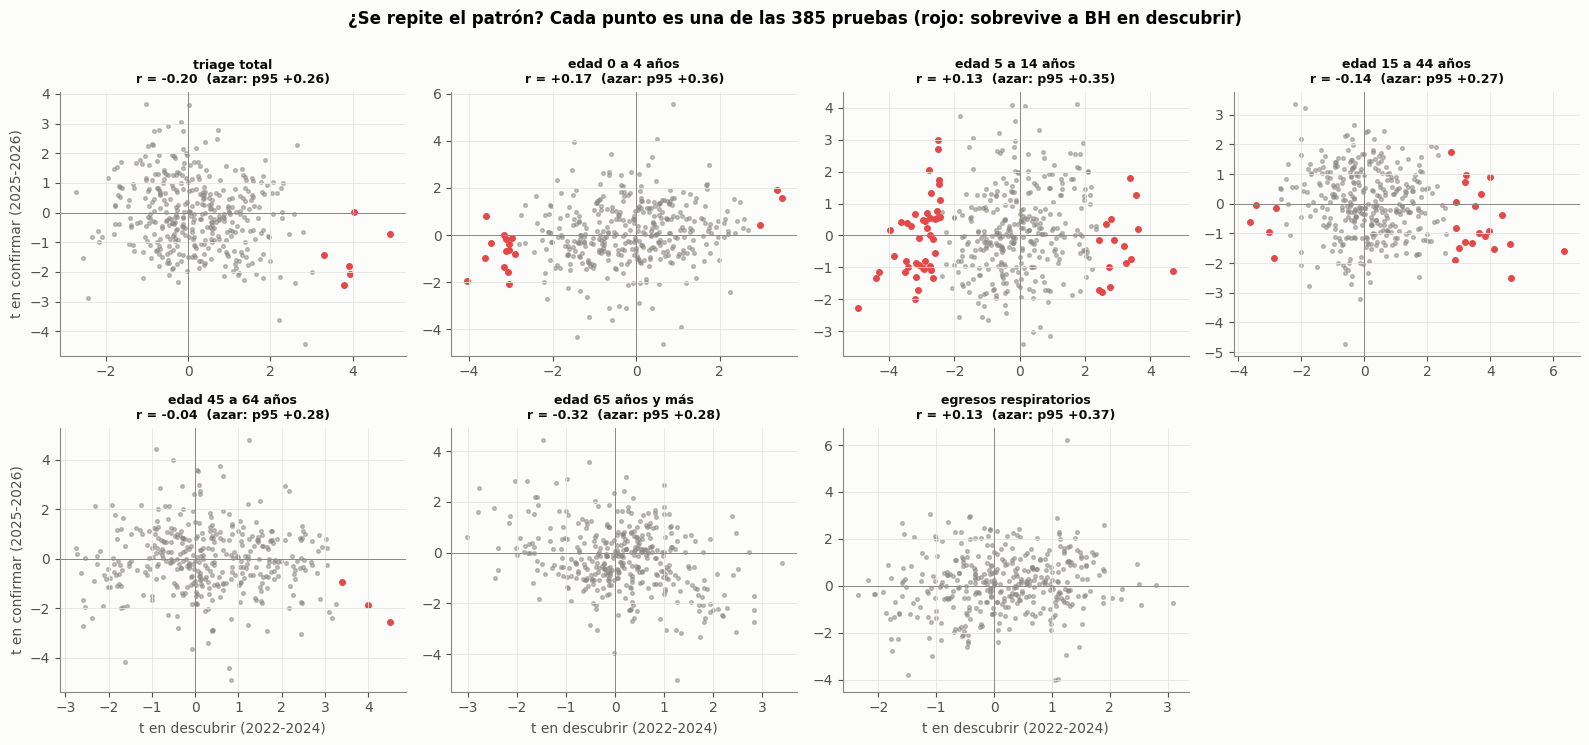

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7.4)); axes = axes.ravel()
for ax, n in zip(axes, EV):
    T = EV[n]["T"]
    ax.scatter(T.t, T.t_conf, s=7, color=MUDO, alpha=.5)
    sv = T[T.sobrevive]; ax.scatter(sv.t, sv.t_conf, s=16, color=ROJO)
    ax.axhline(0, color=MUDO, lw=.7); ax.axvline(0, color=MUDO, lw=.7)
    ax.set_title(f"{n}\nr = {EV[n]['resumen']['r(t desc., t conf.)']:+.2f}  (azar: p95 {EV[n]['resumen']['r azar (p95)']:+.2f})", fontsize=9)
axes[-1].axis("off")
for ax in axes[4:7]: ax.set_xlabel("t en descubrir (2022-2024)")
for ax in axes[::4]: ax.set_ylabel("t en confirmar (2025-2026)")
fig.suptitle("¿Se repite el patrón? Cada punto es una de las 385 pruebas (rojo: sobrevive a BH en descubrir)", fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

In [17]:
# ¿Podía el diseño ver un efecto? Efecto mínimo que se distingue con 80 % de potencia (2,8 errores típicos) y con el umbral de BH (≈ 3,3 errores típicos)
mde = pd.DataFrame({n: {"error típico mediano (% por 1 sd)": 100 * (np.exp(EV[n]["T"].se.median()) - 1),
                        "efecto mínimo detectable, p < 0,05 (%)": pct(2.8 * EV[n]["T"].se.median()),
                        "efecto mínimo para sobrevivir a BH (%)": pct(3.3 * EV[n]["T"].se.median()),
                        "mayor |efecto| observado en descubrir (%)": EV[n]["T"]["efecto %"].abs().max()} for n in EV}).T
mde.round(1)

,error típico mediano (% por 1 sd),"efecto mínimo detectable, p < 0,05 (%)",efecto mínimo para sobrevivir a BH (%),mayor |efecto| observado en descubrir (%)
triage total,0.4,1.2,1.5,1.8
edad 0 a 4 años,2.0,5.6,6.6,7.6
edad 5 a 14 años,1.8,5.0,5.9,11.1
edad 15 a 44 años,0.5,1.5,1.8,2.9
edad 45 a 64 años,0.6,1.7,2.0,3.0
edad 65 años y más,0.7,2.0,2.3,2.7
egresos respiratorios,2.3,6.5,7.7,9.2


La figura de dispersión muestra el patrón completo, no solo los supervivientes. Si el clima tuviera un efecto estable, los
puntos se ordenarían a lo largo de la diagonal (t positivo con t positivo). Lo que se ve es una nube sin pendiente en todas las
bandas. En el total y en 65 años y más la nube tiene pendiente **negativa** (r = −0,20 y −0,32): lo que parecía asociarse en
2022-2024 tiende a asociarse en sentido contrario en 2025-2026.

**¿Podía el diseño ver un efecto?** Con el error típico de cada serie, el efecto mínimo que se distingue con 80 % de potencia es:

| Desenlace | Mínimo con p < 0,05 | Mínimo para sobrevivir a BH | Mayor |efecto| observado |
|---|---|---|---|
| Triage total | 1,2 % | 1,5 % | 1,8 % |
| 0 a 4 años | 5,6 % | 6,6 % | 7,6 % |
| 5 a 14 años | 5,0 % | 5,9 % | 11,1 % |
| 15 a 44 años | 1,5 % | 1,8 % | 2,9 % |
| 45 a 64 años | 1,7 % | 2,0 % | 3,0 % |
| 65 años y más | 2,0 % | 2,3 % | 2,7 % |
| Egresos respiratorios | 6,5 % | 7,7 % | 9,2 % |

Es un efecto por desviación típica de la variable. Con esta potencia, **un resultado nulo en el total y en los adultos
descarta efectos mayores de 1,2 a 2 %, pero no los menores**, y en los niños y en los egresos respiratorios solo descarta
efectos mayores de 5 a 6,5 %. El efecto de un cambio brusco de temperatura sobre las urgencias totales que publica la literatura
(+1,44 % por °C, Wang et al., 2022, doi:10.1016/j.envres.2022.113963) cae justo en el borde de lo que este diseño distingue. Por
eso la conclusión es «no se puede separar del azar», no «no hay efecto».

## 4.3 La forma de la variable: transición o nivel

In [18]:
def forma_general(f):
    if f == "nivel": return "nivel"
    if f == "anomalía": return "nivel como anomalía contra el mes"
    if f.startswith("cambio"): return "transición: cambio a 1, 2 o 4 semanas"
    if f.startswith("días"): return "extremos de la semana"
    if f.startswith("giro"): return "transición de temporada (giro)"
    return "temporada (lluvia acumulada 4 y 8 semanas)"
TT = pd.concat([r["T"].assign(desenlace=n) for n, r in EV.items()])
TT["grupo"] = TT.forma.map(forma_general)
def res_forma(g):
    pos = g[g.p < .05]
    return pd.Series({"pruebas": len(g), "% con p < 0,05 (descubrir)": 100 * (g.p < .05).mean(), "% con p < 0,05 (confirmar)": 100 * (g.p_conf < .05).mean(),
                      "|t| medio (descubrir)": g.t.abs().mean(), "|t| medio (confirmar)": g.t_conf.abs().mean(),
                      "% del mismo signo en confirmar (las de p < 0,05)": 100 * (np.sign(pos.b) == np.sign(pos.b_conf)).mean()})
FORMAS = TT.groupby("grupo").apply(res_forma)
print("referencia si no hubiera nada: |t| medio ≈ 0,8; 5 % con p < 0,05; 50 % del mismo signo")
FORMAS.round(1)

referencia si no hubiera nada: |t| medio ≈ 0,8; 5 % con p < 0,05; 50 % del mismo signo


,pruebas,"% con p < 0,05 (descubrir)","% con p < 0,05 (confirmar)",|t| medio (descubrir),|t| medio (confirmar),"% del mismo signo en confirmar (las de p < 0,05)"
grupo,,,,,,
extremos de la semana,630.0,18.4,13.2,1.2,1.0,40.5
nivel,385.0,20.8,13.2,1.2,1.0,51.2
nivel como anomalía contra el mes,385.0,21.3,12.2,1.3,1.0,50.0
temporada (lluvia acumulada 4 y 8 semanas),70.0,31.4,14.3,1.5,1.1,54.5
transición de temporada (giro),70.0,1.4,15.7,0.6,1.2,0.0
"transición: cambio a 1, 2 o 4 semanas",1155.0,3.1,9.6,0.7,0.9,61.1


In [19]:
filas = []
for n, r in EV.items():
    s = r["T"][r["T"].sobrevive]
    for _, x in s.sort_values("p").head(6).iterrows():
        filas.append({"desenlace": n, "variable": x.variable, "forma": x.forma, "rezago (sem)": x.rezago, "efecto % (descubrir)": x["efecto %"], "p": x.p, "efecto % (confirmar)": x["efecto % conf"], "p (confirmar)": x.p_conf, "se confirma": x.confirma})
pd.DataFrame(filas).round({"efecto % (descubrir)": 1, "efecto % (confirmar)": 1, "p": 5, "p (confirmar)": 3}) if filas else "ninguna sobrevive"

,desenlace,variable,forma,rezago (sem),efecto % (descubrir),p,efecto % (confirmar),p (confirmar),se confirma
0,triage total,temp. máxima,días > p90,5,1.8,0.00000,-1.3,0.462,False
1,triage total,humedad,días < p10,5,1.4,0.00006,0.0,0.977,False
2,triage total,temp. mínima,días > p90,5,1.2,0.00008,-1.8,0.038,False
3,triage total,temp. mínima,anomalía,5,1.6,0.00009,-2.0,0.069,False
4,triage total,temp. media,días > p90,5,1.8,0.00015,-1.7,0.014,False
5,triage total,amplitud térmica,días > p90,1,1.3,0.00095,-1.1,0.152,False
6,edad 0 a 4 años,temp. media,nivel,5,-7.6,0.00005,-6.3,0.053,False
7,edad 0 a 4 años,temp. media,anomalía,5,-6.9,0.00029,-2.9,0.334,False
8,edad 0 a 4 años,temp. media,días > p90,2,-5.7,0.00034,2.4,0.415,False
9,edad 0 a 4 años,humedad,anomalía,3,4.9,0.00050,4.7,0.118,False


**La transición, medida como cambio semanal, tiene menos señal que el nivel.** Agrupando las 2.695 pruebas de los siete
desenlaces por la forma de la variable:

| Forma | Pruebas | % con p < 0,05 (descubrir) | |t| medio (descubrir) | % con p < 0,05 (confirmar) | Mismo signo en confirmar |
|---|---|---|---|---|---|
| Nivel | 385 | 20,8 | 1,2 | 13,2 | 51,2 % |
| Anomalía contra el mes | 385 | 21,3 | 1,3 | 12,2 | 50,0 % |
| Extremos de la semana | 630 | 18,4 | 1,2 | 13,2 | 40,5 % |
| Temporada (lluvia de 4 y 8 semanas) | 70 | 31,4 | 1,5 | 14,3 | 54,5 % |
| Transición: cambio a 1, 2 o 4 semanas | 1.155 | 3,1 | 0,7 | 9,6 | 61,1 % |
| Transición de temporada (giro) | 70 | 1,4 | 0,6 | 15,7 | 0 % |

La referencia no es el 5 %: con la estructura real, el azar da entre el 9 y el 12 % de pruebas con p < 0,05. Los niveles quedan
por encima de eso en descubrir (18 a 31 %), pero **en confirmar el signo coincide en la mitad de los casos**, es decir, una
moneda. Las transiciones quedan por debajo del azar en descubrir (3,1 % y 1,4 %) y, por tanto, **con esta definición (el cambio
de una semana frente a las anteriores, o el giro de la temporada) la hipótesis de que importa la transición y no el nivel no se
sostiene**. No descarta transiciones de otra escala o de otra forma, como las que se miran en la sección 7.

**Lo que más destaca entre las supervivientes** son los días calurosos o las noches cálidas (sobre el p90) cinco semanas antes: +1,8 % del total,
+2,7 % de 15 a 44 años y +2,4 % de 45 a 64. En confirmar esas mismas pruebas cambian de signo (−1,3 %, −2,9 %, −2,9 %). Es la firma
de «semanas soleadas y cálidas» de 2022-2024, que coincide con el año cálido de El Niño de 2023-2024, año récord de triage, y que no
se repite en 2025-2026. Con un solo episodio de El Niño en la ventana, la firma no se puede separar del año.

**La única confirmación de 5 a 14 años** es la temperatura media del nivel semanal a 5 semanas: −11,1 % en descubrir y −6,4 % en
confirmar (p = 0,023). Una semana más fría anticipa más triage escolar cinco semanas después. En los adultos el signo es el
opuesto (+2,5 a +2,9 %). El sentido para los niños concuerda con el mecanismo respiratorio del frío, pero es una prueba entre 385
y no resiste por sí sola.

## 4.4 El clima completo desde 2010

El consenso de clima solo cubre 2020-2026. El clima completo (ERA5 y NASA POWER en La Nubia, desde 2010) añade horas de sol,
nubosidad, déficit de presión de vapor, rachas y la transición de seco a lluvioso, en niveles de 7 y 28 días y en cambio de la
última semana frente a las tres anteriores. Es la familia con la que se midió originalmente la IRA de la ciudad. Se aplica aquí
exactamente el mismo barrido sobre los siete desenlaces, y además el diseño anterior (rezagos de 0 a 6) sobre el triage total,
para reconciliar con él.

In [20]:
# ---- Clima completo desde 2010 (ERA5 y NASA POWER en La Nubia): horas de sol, nubosidad, déficit de presión de vapor, rachas y transiciones
Fc = ix.clima_semanal().loc["2011-10-01":]
FORMA_C = lambda c: ("transición (cambio de la semana frente a las 3 anteriores)" if c.endswith("_cambio") else "nivel de 7 días" if c.endswith("_7d")
                     else "nivel de 28 días" if c.endswith("_28d") else "racha o extremo")
Xc = (Fc - Fc.loc[:"2024"].mean()) / Fc.loc[:"2024"].std()
print(f"{Xc.shape[1]} variables semanales de clima completo, {Xc.index[0]:%Y-%m-%d} a {Xc.index[-1]:%Y-%m-%d}; por tipo:", pd.Series({c: FORMA_C(c) for c in Xc}).value_counts().to_dict())

38 variables semanales de clima completo, 2011-10-02 a 2026-09-27; por tipo: {'nivel de 7 días': 12, 'nivel de 28 días': 11, 'transición (cambio de la semana frente a las 3 anteriores)': 11, 'racha o extremo': 4}


In [21]:
t0 = time.time()
EVC = {nombre: evaluar(s, Xc, REZ_MEC, DESC, CONF, fijo="mes+año", n_sim=N_SIM, semilla=5) for nombre, s in SALIDAS.items()}
EVC0 = evaluar(Y.y, Xc, range(0, 7), DESC, CONF, fijo="mes+año", n_sim=N_SIM, semilla=6)      # el diseño del barrido anterior: 38 variables x rezagos 0 a 6
EVC0_m = evaluar(Y.y, Xc, range(0, 7), DESC, CONF, fijo="mes", n_sim=N_SIM, semilla=6)
EVC0_n = evaluar(Y.y, Xc, range(0, 7), DESC, CONF, fijo=None, n_sim=N_SIM, semilla=6)
print(f"[{time.time()-t0:.0f} s]")
cl_ = ["pruebas", "p<0,05", "azar (media)", "azar (p95)", "p emp. p<0,05", "sobreviven BH", "BH azar (media)", "BH azar (p95)", "p emp. BH", "se confirman", "conf. azar (media)", "r(t desc., t conf.)", "r azar (p95)", "p emp. r"]
tab = tabla_resumen({**EVC, "triage total, rezagos 0 a 6": EVC0}, cl_)
display(tab.round(3))

SENS = pd.DataFrame({k: {"pruebas": r["resumen"]["pruebas"], "p < 0,05": r["resumen"]["p<0,05"], "azar (media)": r["resumen"]["azar (media)"], "sobreviven a BH": r["resumen"]["sobreviven BH"],
                         "BH azar (media)": r["resumen"]["BH azar (media)"], "BH azar (p95)": r["resumen"]["BH azar (p95)"], "p empírico BH": r["resumen"]["p emp. BH"], "se confirman": r["resumen"]["se confirman"]}
                     for k, r in {"sin efectos fijos": EVC0_n, "mes fijo": EVC0_m, "mes y año fijos": EVC0}.items()}).T
SENS.round(2)

[465 s]


,pruebas,"p<0,05",azar (media),azar (p95),"p emp. p<0,05",sobreviven BH,BH azar (media),BH azar (p95),p emp. BH,se confirman,conf. azar (media),"r(t desc., t conf.)",r azar (p95),p emp. r
triage total,190.0,22.0,24.380,60.0,0.435,4.0,8.940,49.05,0.336,0.0,0.837,-0.542,0.419,0.993
edad 0 a 4 años,190.0,43.0,25.320,45.0,0.093,24.0,6.750,25.05,0.063,2.0,0.873,0.355,0.444,0.150
edad 5 a 14 años,190.0,47.0,28.343,60.0,0.153,44.0,11.217,45.00,0.056,0.0,1.650,-0.032,0.527,0.528
edad 15 a 44 años,190.0,41.0,21.920,54.0,0.113,27.0,6.340,41.00,0.073,0.0,0.530,-0.417,0.398,0.960
edad 45 a 64 años,190.0,41.0,26.360,53.0,0.259,23.0,11.877,41.00,0.259,0.0,0.580,-0.251,0.360,0.817
edad 65 años y más,190.0,20.0,29.083,61.0,0.651,5.0,13.980,48.05,0.505,0.0,1.327,-0.233,0.477,0.767
egresos respiratorios,190.0,10.0,22.567,50.0,0.734,0.0,8.407,40.00,1.000,0.0,1.020,0.042,0.408,0.485
"triage total, rezagos 0 a 6",266.0,46.0,34.817,77.0,0.239,18.0,12.737,59.00,0.239,0.0,1.270,-0.528,0.381,0.977


,pruebas,"p < 0,05",azar (media),sobreviven a BH,BH azar (media),BH azar (p95),p empírico BH,se confirman
sin efectos fijos,266.0,18.0,20.83,0.0,5.92,49.2,1.00,0.0
mes fijo,266.0,40.0,32.37,6.0,13.81,98.0,0.31,0.0
mes y año fijos,266.0,46.0,34.82,18.0,12.74,59.0,0.24,0.0


In [22]:
# ---- ¿A qué mes pertenece una semana que cruza dos meses? Mismo barrido sobre el total (clima completo, rezagos 0 a 6, mes y año fijos), con statsmodels
def barrido_sm(y, X, rezagos, ancla):
    idx = y.dropna().index; ref = idx if ancla == "primer día de la semana" else idx + pd.Timedelta(days=3)
    ex = [pd.get_dummies(pd.Index(ref.month), prefix="m", drop_first=True).set_index(idx).astype(float),
          pd.get_dummies(pd.Index(ref.year), prefix="a", drop_first=True).set_index(idx).astype(float)]
    p = []
    for c in X:
        for k in rezagos:
            D = pd.concat([y.rename("y"), X[c].shift(k).rename("x")] + ex, axis=1).loc[idx].dropna()
            p.append(sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4}).pvalues["x"])
    p = np.array(p); return {"pruebas": len(p), "p < 0,05": int((p < .05).sum()), "sobreviven a BH": int(bh(p).sum())}
REC = pd.DataFrame({a: barrido_sm(Y.y.loc[DESC[0]:DESC[1]], Xc, range(0, 7), a) for a in ["primer día de la semana", "mitad de la semana"]}).T
REC.index.name = "el mes de la semana se toma del"
REC

,pruebas,"p < 0,05",sobreviven a BH
el mes de la semana se toma del,,,
primer día de la semana,266,63,36
mitad de la semana,266,46,18


**Con el clima completo ocurre lo mismo.**

| Desenlace | Sobreviven a BH | Azar: media (p95) | p empírico | Se confirman | r (azar p95) |
|---|---|---|---|---|---|
| Triage total | 4 | 8,9 (49,1) | 0,34 | 0 | −0,54 (0,42) |
| 0 a 4 años | 24 | 6,8 (25,1) | 0,06 | 2 | +0,36 (0,44) |
| 5 a 14 años | 44 | 11,2 (45,0) | 0,06 | 0 | −0,03 (0,53) |
| 15 a 44 años | 27 | 6,3 (41,0) | 0,07 | 0 | −0,42 (0,40) |
| 45 a 64 años | 23 | 11,9 (41,0) | 0,26 | 0 | −0,25 (0,36) |
| 65 años y más | 5 | 14,0 (48,1) | 0,50 | 0 | −0,23 (0,48) |
| Egresos respiratorios | 0 | 8,4 (40,0) | 1,00 | 0 | +0,04 (0,41) |

Otra vez las bandas de 0 a 4, 5 a 14 y 15 a 44 años se acercan al borde (p empírico 0,06 a 0,07) y otra vez casi nada se
confirma (2 de 190 pruebas en 0 a 4 años). Para el **total**, la correlación entre los t de descubrir y de confirmar es
**−0,54**, mientras que el azar da un percentil 95 de +0,42: solo 2 de los 300 desplazamientos dan una correlación igual o más
negativa (p = 0,010). Es decir, el patrón de 2022-2024 no solo no se repite: **se invierte** con más intensidad de la que produce el azar. Lo mismo ocurre con el total en las otras tres familias que usan clima completo o sus índices (r = −0,53, −0,43 y −0,48; p entre 0,027 y 0,043).

**Reconciliación con el barrido del cuaderno 17.** Aquel cuaderno reportó 36 supervivientes en el triage total (rezagos de 0 a 6,
mes y año fijos). El mismo diseño da aquí 18 supervivientes, y el azar, 12,7 de media (percentil 95: 59; p empírico 0,24). La
diferencia entre 36 y 18 sale de un detalle: **a qué mes pertenece una semana que cruza dos meses**. Con el mes del primer día de
la semana se reproducen los 36; con el mes de la mitad de la semana, 18 (tabla de sensibilidad). Cuando el resultado depende de
una convención tan menor, es señal de que no es robusto. Y quitar los efectos fijos lo cambia más aún: sin ellos no sobrevive
ninguna prueba, con mes fijo sobreviven 6, con mes y año fijos 18, y en ninguno de los tres el número supera lo que da el azar.

Los 36 supervivientes del cuaderno 17 y los 34 del barrido original son, entonces, la misma situación: una señal que existe en
2022-2024, pequeña, que aparece o desaparece según el control, y que el azar con esta estructura puede producir.

## 4.5 Los índices del clima completo por banda de edad

Los siete índices de estado y de cambio del clima completo y dos rachas (nueve variables) son el conjunto con el que se había
observado que los mayores de 65 años suben con la lluvia reciente. Se repite aquí con el desplazamiento circular y con la
confirmación en 2025-2026. Después se calibra ese caso con 2.000 desplazamientos, porque una variable que cambia despacio, como
los días desde la última semana muy lluviosa, tiene pocas «observaciones independientes» y los errores HAC la favorecen.

In [23]:
# ---- Los índices del clima completo (cuaderno 21): ¿se repite en las bandas de edad lo que allí apareció?
IC = ix.indices_clima()
IC = IC / IC.loc[:"2024"].std()
IC = IC.loc["2022-01-01":]
t0 = time.time()
EV21 = {nombre: evaluar(s, IC, REZ_MEC, DESC, CONF, fijo="mes+año", n_sim=N_SIM, semilla=3) for nombre, s in SALIDAS.items()}
print(f"[{time.time()-t0:.0f} s]")
print(tabla_resumen(EV21, ["pruebas", "p<0,05", "azar (media)", "p emp. p<0,05", "sobreviven BH", "BH azar (media)", "p emp. BH", "se confirman", "conf. azar (media)", "r(t desc., t conf.)", "p emp. r"]).round(3).T.to_string())
for k, r in EV21.items():
    s = r["T"][r["T"].sobrevive]
    if len(s): print(k); print(s[["variable", "rezago", "efecto %", "efecto % conf", "p", "p_conf", "confirma"]].round(4).to_string())

[89 s]
                     triage total  edad 0 a 4 años  edad 5 a 14 años  edad 15 a 44 años  edad 45 a 64 años  edad 65 años y más  egresos respiratorios
pruebas                    45.000           45.000            45.000             45.000             45.000              45.000                 45.000
p<0,05                      9.000            5.000             7.000              9.000             11.000               8.000                  2.000
azar (media)                5.177            5.537             6.320              5.077              5.417               5.543                  5.253
p emp. p<0,05               0.199            0.651             0.405              0.169              0.100               0.256                  0.877
sobreviven BH               5.000            1.000             5.000              7.000              5.000               5.000                  0.000
BH azar (media)             1.677            1.943             2.467              1.753      

In [24]:
# ---- Calibración de un caso: los mayores y la lluvia reciente (días desde la última semana muy lluviosa), con 2.000 desplazamientos circulares
xv = IC["dias_desde_semana_muy_lluviosa"]
filas = []
for nombre in ["edad 65 años y más", "triage total"]:
    y_ = SALIDAS[nombre]
    idx = y_.loc[DESC[0]:DESC[1]].index; fd = _ajustador(idx, "mes+año"); yv = y_.reindex(idx).values.astype(float)
    idc = y_.loc[CONF[0]:CONF[1]].index; fc = _ajustador(idc, "mes+año"); yc_ = y_.reindex(idc).values.astype(float)
    XLd = [xv.shift(k).reindex(idx).values.astype(float) for k in REZ_MEC]; XLc = [xv.shift(k).reindex(idc).values.astype(float) for k in REZ_MEC]
    obs = [fd(yv, x) for x in XLd]; conf = [fc(yc_, x) for x in XLc]
    rng = np.random.default_rng(7)
    nul = np.array([[b / se for b, se in (fd(np.roll(yv, s), x) for x in XLd)] for s in rng.integers(8, len(yv) - 8, 2000)])
    for i, k in enumerate(REZ_MEC):
        t_o = obs[i][0] / obs[i][1]
        filas.append({"desenlace": nombre, "rezago (sem)": k, "efecto % (descubrir)": pct(obs[i][0]), "t HAC": t_o, "p HAC": float(pval(*obs[i])),
                      "p con el desenlace desplazado": (1 + (np.abs(nul[:, i]) >= abs(t_o)).sum()) / 2001,
                      "|t| que supera el 5 % de los desplazamientos": np.quantile(np.abs(nul[:, i]), .95),
                      "efecto % (confirmar)": pct(conf[i][0]), "p HAC (confirmar)": float(pval(*conf[i]))})
MAY = pd.DataFrame(filas)
MAY.round({"efecto % (descubrir)": 1, "t HAC": 2, "p HAC": 5, "p con el desenlace desplazado": 3, "|t| que supera el 5 % de los desplazamientos": 2, "efecto % (confirmar)": 1, "p HAC (confirmar)": 3})

,desenlace,rezago (sem),efecto % (descubrir),t HAC,p HAC,p con el desenlace desplazado,|t| que supera el 5 % de los desplazamientos,efecto % (confirmar),p HAC (confirmar)
0,edad 65 años y más,1,-5.0,-5.12,0.00000,0.000,3.08,4.2,0.033
1,edad 65 años y más,2,-5.4,-5.96,0.00000,0.000,3.37,2.2,0.301
2,edad 65 años y más,3,-4.9,-4.90,0.00000,0.000,3.37,1.2,0.376
3,edad 65 años y más,4,-3.7,-3.15,0.00163,0.090,3.53,1.1,0.519
4,edad 65 años y más,5,-3.5,-3.03,0.00246,0.099,3.49,0.1,0.936
5,triage total,1,-2.2,-2.78,0.00536,0.108,3.12,0.8,0.480
6,triage total,2,-2.1,-2.73,0.00627,0.097,3.30,-0.3,0.847
7,triage total,3,-2.1,-2.59,0.00947,0.128,3.71,-0.2,0.854
8,triage total,4,-1.9,-2.31,0.02069,0.197,3.76,-0.4,0.660
9,triage total,5,-1.2,-1.23,0.21776,0.509,3.63,-0.2,0.844


**La asociación de los mayores con la lluvia reciente existe en 2022-2024, y no se sostiene después.** Para los nueve índices
del clima completo, los mayores de 65 años tienen 5 pruebas supervivientes (azar: 2,5; p empírico 0,26), 7 los adultos de 15 a 44
(azar: 1,8; p empírico 0,07) y ninguna prueba se confirma en ninguna banda. Los mayores de 65 vienen de una sola variable, los
**días desde la última semana muy lluviosa**: un coeficiente negativo significa que, cuanto más reciente la lluvia fuerte, más
triage de mayores.

La calibración de ese caso, con 2.000 desplazamientos:

| Semanas de rezago | Efecto por 1 sd (descubrir) | |t| | |t| que supera el 5 % del azar | Efecto en confirmar |
|---|---|---|---|---|
| 1 | −5,0 % | 5,1 | 3,1 | **+4,2 %** (p = 0,033) |
| 2 | −5,4 % | 6,0 | 3,4 | +2,2 % |
| 3 | −4,9 % | 4,9 | 3,4 | +1,2 % |
| 4 | −3,7 % | 3,2 | 3,5 | +1,1 % |
| 5 | −3,5 % | 3,0 | 3,5 | +0,1 % |

Lo observado a 1 a 3 semanas supera, en descubrir, a los 2.000 desplazamientos (ninguno da un |t| igual), así que **la asociación
en 2022-2024 es real como descripción de ese periodo**. Es coherente con la de +4,6 % que se había observado en esta banda por
otra vía. Pero hay tres cautelas: la variable fue escogida por ser la mejor de la familia, lo que infla su p; el número de
supervivientes de la familia no supera al azar; y en 2025-2026 **el signo se invierte** (+4,2 % a 1 semana). Para el total el
mismo coeficiente es de −2,2 % y el azar lo alcanza en el 10 a 13 % de los desplazamientos.

Los errores HAC subestiman la incertidumbre de una variable que cambia despacio: el |t| que el azar supera el 5 % de las veces
es de 3,1 a 3,5 y no de 1,96. Por eso aquí se usa el desplazamiento y no el p nominal.

---
# 5. Los estados del clima: componentes principales

Se ajustan en las **anomalías semanales** de 10 variables (sin las horas de lluvia, por calidad):
- estandarizadas con la media y la desviación de descubrir;
- **ajustados solo en descubrir** y proyectados sobre todo el resto.

Cada componente se orienta para que su carga mayor sea positiva y se mide en desviaciones típicas de descubrir.

ajustado en 148 semanas de descubrir; varianza explicada: {'CP1': 51.6, 'CP2': 24.6, 'CP3': 7.6, 'CP4': 6.2} acumulada 90.0 %
semanas proyectadas en confirmar: 85 ; varianza de los índices en confirmar (1 = igual que en descubrir): {'CP1': 0.74, 'CP2': 0.64, 'CP3': 1.45, 'CP4': 1.26}


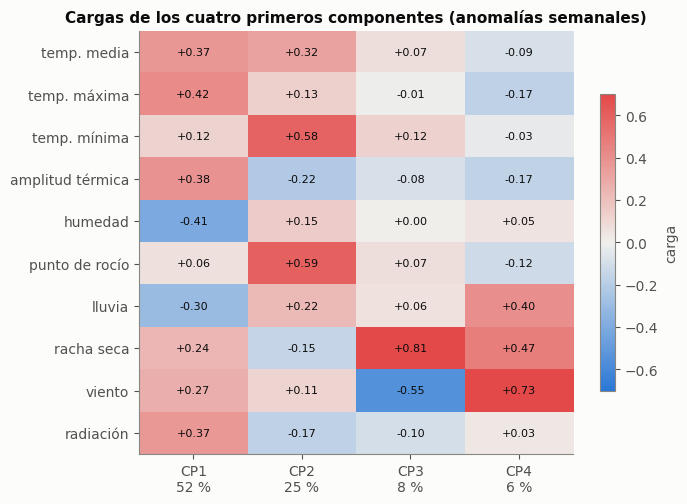

,CP1,CP2,CP3,CP4
temp. media,0.37,0.32,0.07,-0.09
temp. máxima,0.42,0.13,-0.01,-0.17
temp. mínima,0.12,0.58,0.12,-0.03
amplitud térmica,0.38,-0.22,-0.08,-0.17
humedad,-0.41,0.15,0.00,0.05
punto de rocío,0.06,0.59,0.07,-0.12
lluvia,-0.30,0.22,0.06,0.40
racha seca,0.24,-0.15,0.81,0.47
viento,0.27,0.11,-0.55,0.73
radiación,0.37,-0.17,-0.10,0.03


In [25]:
VARS_PCA = ["temp. media", "temp. máxima", "temp. mínima", "amplitud térmica", "humedad", "punto de rocío", "lluvia", "racha seca", "viento", "radiación"]
A = anom[VARS_PCA]
mu, sd = A.loc[DESC[0]:DESC[1]].mean(), A.loc[DESC[0]:DESC[1]].std()
Z = (A - mu) / sd
ajuste = Z.loc[DESC[0]:DESC[1]].dropna()
pca = PCA(n_components=4).fit(ajuste.values)
cargas = pd.DataFrame(pca.components_.T, index=VARS_PCA, columns=[f"CP{i+1}" for i in range(4)])
signo = np.sign(cargas.apply(lambda c: c[c.abs().idxmax()])); cargas = cargas * signo      # la carga mayor, positiva
completas = Z.dropna()
IDX = pd.DataFrame(pca.transform(completas.values) * signo.values, index=completas.index, columns=cargas.columns).reindex(SEM)
IDX = IDX / IDX.loc[DESC[0]:DESC[1]].std()             # en desviaciones típicas de descubrir
print(f"ajustado en {len(ajuste)} semanas de descubrir; varianza explicada:",
      dict(zip(cargas.columns, (100 * pca.explained_variance_ratio_).round(1))), f"acumulada {100 * pca.explained_variance_ratio_.sum():.1f} %")
print("semanas proyectadas en confirmar:", IDX.loc[CONF[0]:CONF[1]].notna().all(axis=1).sum(),
      "; varianza de los índices en confirmar (1 = igual que en descubrir):", IDX.loc[CONF[0]:CONF[1]].var().round(2).to_dict())
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(cargas.values, cmap=DIVERGENTE, vmin=-.7, vmax=.7, aspect="auto")
for i in range(cargas.shape[0]):
    for j in range(cargas.shape[1]):
        ax.text(j, i, f"{cargas.values[i, j]:+.2f}", ha="center", va="center", fontsize=8, color=TINTA)
ax.set_xticks(range(4), [f"{c}\n{100 * r:.0f} %" for c, r in zip(cargas.columns, pca.explained_variance_ratio_)])
ax.set_yticks(range(len(VARS_PCA)), VARS_PCA); ax.grid(False); plt.colorbar(im, ax=ax, shrink=.7, label="carga")
ax.set_title("Cargas de los cuatro primeros componentes (anomalías semanales)"); plt.show()
cargas.round(2)

**Cuatro estados explican el 90,0 % de la varianza** de las anomalías semanales (148 semanas de descubrir):

| Índice | Varianza | Cargas que lo definen | Qué es |
|---|---|---|---|
| **CP1 soleado y seco** | 51,6 % | máxima +0,42, amplitud +0,38, radiación +0,37, temp. media +0,37; humedad −0,41, lluvia −0,30 | Cielo despejado: días calientes, noches frías, poca lluvia. En negativo, nublado, húmedo y lluvioso |
| **CP2 bochorno húmedo** | 24,6 % | punto de rocío +0,59, mínima +0,58, media +0,32, lluvia +0,22 | Aire cargado de humedad y noches templadas |
| **CP3 racha seca en calma** | 7,6 % | racha seca +0,81, viento −0,55 | Días seguidos sin lluvia y sin viento |
| **CP4 ventoso** | 6,2 % | viento +0,73, racha seca +0,47, lluvia +0,40 | Semanas de viento |

En confirmar, CP1 y CP2 varían menos que en descubrir (0,74 y 0,64 de la varianza) y CP3 y CP4 más (1,45 y 1,26).

**Límite.** CP3 y CP4 cargan sobre la racha seca, que es la variable menos fiable (sección 1): se leen con cautela.

In [26]:
NOMBRES_CP = ['CP1 soleado y seco', 'CP2 bochorno húmedo', 'CP3 racha seca en calma', 'CP4 ventoso']   # leídos de las cargas de arriba
IDX = IDX.rename(columns=dict(zip(cargas.columns, NOMBRES_CP)))
t0 = time.time()
EVP = {nombre: evaluar(s, IDX, REZ_MEC, DESC, CONF, fijo="mes+año", n_sim=N_SIM, semilla=4) for nombre, s in SALIDAS.items()}
print(f"[{time.time()-t0:.0f} s]")
tabla_resumen(EVP, ["pruebas", "p<0,05", "azar (media)", "p emp. p<0,05", "sobreviven BH", "BH azar (media)", "p emp. BH", "se confirman", "conf. azar (media)", "r(t desc., t conf.)", "p emp. r"]).round(2)

[40 s]


,pruebas,"p<0,05",azar (media),"p emp. p<0,05",sobreviven BH,BH azar (media),p emp. BH,se confirman,conf. azar (media),"r(t desc., t conf.)",p emp. r
triage total,20.0,2.0,1.87,0.52,0.0,0.91,1.00,0.0,0.05,-0.48,0.97
edad 0 a 4 años,20.0,4.0,2.42,0.20,3.0,0.74,0.13,0.0,0.08,0.38,0.09
edad 5 a 14 años,20.0,7.0,3.49,0.12,7.0,1.60,0.05,0.0,0.16,0.28,0.14
edad 15 a 44 años,20.0,4.0,2.00,0.18,1.0,0.61,0.35,0.0,0.02,-0.15,0.73
edad 45 a 64 años,20.0,6.0,2.50,0.04,3.0,0.91,0.14,0.0,0.05,-0.34,0.92
edad 65 años y más,20.0,2.0,2.75,0.72,1.0,1.23,0.47,0.0,0.10,-0.38,0.94
egresos respiratorios,20.0,2.0,2.37,0.66,0.0,0.96,1.00,0.0,0.06,0.06,0.43


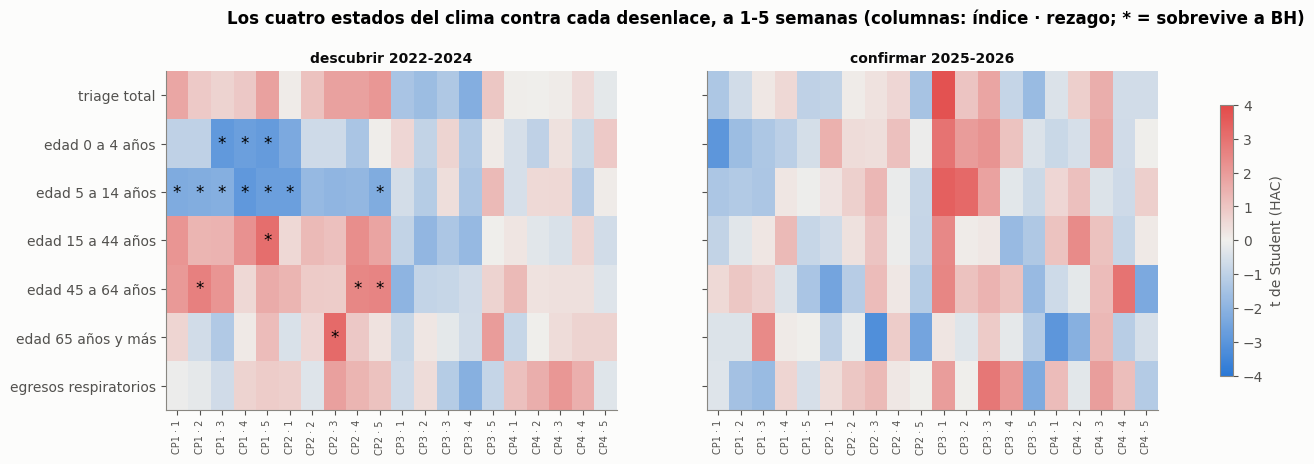

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.4), sharey=True)
orden = [(c, k) for c in IDX.columns for k in REZ_MEC]
for ax, col, tit in [(axes[0], "t", "descubrir 2022-2024"), (axes[1], "t_conf", "confirmar 2025-2026")]:
    M = np.array([[EVP[n]["T"].set_index(["variable", "rezago"]).loc[o, col] for o in orden] for n in EVP])
    im = ax.imshow(M, cmap=DIVERGENTE, vmin=-4, vmax=4, aspect="auto")
    if col == "t":
        for i, n in enumerate(EVP):
            sv = EVP[n]["T"].set_index(["variable", "rezago"]).sobrevive
            for j, o in enumerate(orden):
                if sv.loc[o]: ax.text(j, i, "*", ha="center", va="center", fontsize=12)
    ax.set_xticks(range(len(orden)), [f"{c.split(' ')[0]} · {k}" for c, k in orden], rotation=90, fontsize=7)
    ax.set_title(tit, fontsize=10); ax.grid(False)
axes[0].set_yticks(range(len(EVP)), list(EVP))
fig.colorbar(im, ax=axes, shrink=.8, label="t de Student (HAC)")
fig.suptitle("Los cuatro estados del clima contra cada desenlace, a 1-5 semanas (columnas: índice · rezago; * = sobrevive a BH)", fontweight="bold", y=1.02)
plt.show()

In [28]:
filas = []
for n, r in EVP.items():
    for _, x in r["T"][r["T"].sobrevive].iterrows():
        filas.append({"desenlace": n, "índice": x.variable, "rezago (sem)": x.rezago, "efecto % (descubrir)": x["efecto %"], "p": x.p, "efecto % (confirmar)": x["efecto % conf"], "p (confirmar)": x.p_conf})
print("pruebas que sobreviven a BH en descubrir:")
display(pd.DataFrame(filas).round({"efecto % (descubrir)": 1, "efecto % (confirmar)": 1, "p": 5, "p (confirmar)": 3}))
filas = []
for n in ["edad 0 a 4 años", "edad 5 a 14 años"]:
    T = EVP[n]["T"]
    for _, x in T[T.variable.eq("CP1 soleado y seco")].iterrows():
        filas.append({"desenlace": n, "rezago (sem)": x.rezago, "efecto % (descubrir)": x["efecto %"], "p": x.p, "efecto % (confirmar)": x["efecto % conf"], "p (confirmar)": x.p_conf})
print("el estado soleado y seco (CP1) en las dos bandas pediátricas, todos los rezagos:")
pd.DataFrame(filas).round({"efecto % (descubrir)": 1, "efecto % (confirmar)": 1, "p": 4, "p (confirmar)": 3})

pruebas que sobreviven a BH en descubrir:


,desenlace,índice,rezago (sem),efecto % (descubrir),p,efecto % (confirmar),p (confirmar)
0,edad 0 a 4 años,CP1 soleado y seco,3,-5.0,0.00429,-4.6,0.181
1,edad 0 a 4 años,CP1 soleado y seco,4,-4.4,0.00761,-3.3,0.289
2,edad 0 a 4 años,CP1 soleado y seco,5,-6.0,0.00531,-1.3,0.574
3,edad 5 a 14 años,CP1 soleado y seco,1,-4.3,0.02276,-3.0,0.177
4,edad 5 a 14 años,CP1 soleado y seco,2,-4.4,0.02743,-4.5,0.214
5,edad 5 a 14 años,CP1 soleado y seco,3,-3.4,0.03114,-4.5,0.174
6,edad 5 a 14 años,CP1 soleado y seco,4,-4.7,0.00380,0.5,0.829
7,edad 5 a 14 años,CP1 soleado y seco,5,-5.7,0.00724,-0.1,0.973
8,edad 5 a 14 años,CP2 bochorno húmedo,1,-4.9,0.00729,0.5,0.793
9,edad 5 a 14 años,CP2 bochorno húmedo,5,-4.3,0.02478,-3.9,0.413


el estado soleado y seco (CP1) en las dos bandas pediátricas, todos los rezagos:


,desenlace,rezago (sem),efecto % (descubrir),p,efecto % (confirmar),p (confirmar)
0,edad 0 a 4 años,1,-2.4,0.3220,-7.3,0.003
1,edad 0 a 4 años,2,-2.7,0.3292,-5.9,0.095
2,edad 0 a 4 años,3,-5.0,0.0043,-4.6,0.181
3,edad 0 a 4 años,4,-4.4,0.0076,-3.3,0.289
4,edad 0 a 4 años,5,-6.0,0.0053,-1.3,0.574
5,edad 5 a 14 años,1,-4.3,0.0228,-3.0,0.177
6,edad 5 a 14 años,2,-4.4,0.0274,-4.5,0.214
7,edad 5 a 14 años,3,-3.4,0.0311,-4.5,0.174
8,edad 5 a 14 años,4,-4.7,0.0038,0.5,0.829
9,edad 5 a 14 años,5,-5.7,0.0072,-0.1,0.973


**Los estados del clima muestran una dirección estable en los niños y nada más.**

| Desenlace | Sobreviven a BH | Azar (media) | p empírico | Se confirman |
|---|---|---|---|---|
| Triage total | 0 | 0,9 | 1,00 | 0 |
| 0 a 4 años | 3 | 0,7 | 0,13 | 0 |
| 5 a 14 años | 7 | 1,6 | 0,05 | 0 |
| 15 a 44 años | 1 | 0,6 | 0,35 | 0 |
| 45 a 64 años | 3 | 0,9 | 0,14 | 0 |
| 65 años y más | 1 | 1,2 | 0,47 | 0 |
| Egresos respiratorios | 0 | 1,0 | 1,00 | 0 |

- **Las supervivientes de 0 a 4 y de 5 a 14 años son casi todas del estado soleado y seco (CP1), con signo negativo**: las semanas de
  cielo despejado anteceden **menos** triage infantil a 1 a 5 semanas, y las nubladas, húmedas y lluviosas, más. Es el sentido que
  tiene el mecanismo respiratorio y el mismo que se ve en la IRA de la ciudad (sección 6).
- **La dirección se sostiene en 2025-2026 aunque la significación no.** Los diez coeficientes de CP1 en las dos bandas son
  negativos en descubrir (de −2,4 a −6,0 %) y nueve de diez lo son en confirmar (de −0,1 a −7,3 %). La única prueba con p < 0,05 en
  confirmar es la de 0 a 4 años a 1 semana (−7,3 %; p = 0,003), que en descubrir no había sobrevivido. Los rezagos vecinos no son
  pruebas independientes, así que «nueve de diez» es una indicación y no una prueba. Con las 86 semanas de confirmar, las
  bandas pediátricas tienen un error típico tan grande que el mismo efecto casi nunca llega a p < 0,05.
- **En los adultos el signo es el contrario y no se sostiene.** CP1 da +1,8 % en 15 a 44 y en 45 a 64 años, y CP2 +1,5 a +1,6 % en 45 a 64;
  en los mayores de 65, CP2 a 3 semanas pasa de +2,4 % a −3,4 % (p = 0,001) en 2025-2026.
- La correlación del patrón entre periodos es positiva en las bandas de 0 a 4 y de 5 a 14 años (+0,38 y +0,28; p empírico 0,09 y 0,14)
  y negativa en el total (−0,48), con inversión de p = 0,037.

Con estos datos es la señal con más apoyo de las que el clima da sobre el hospital, y se queda en una hipótesis de dirección.

---
# 6. El desenlace intermedio: la IRA de la ciudad

El mecanismo propuesto pasa por la enfermedad respiratoria. Los diagnósticos respiratorios del hospital son egresos (una
tercera parte de quienes llegan) y el motivo de consulta respiratorio de triage no está disponible como serie agregada, así que
el desenlace intermedio que sí existe con historia larga es la **IRA de Manizales** del SIVIGILA (consultas externas y de
urgencias de la ciudad, por semana, 2012-2025). Con 13 años y 585 semanas utilizables, la medición tiene una potencia que
el triage no tiene. La COVID (2020-03 a 2021-12) se deja como nula. El diseño es el mismo: 38 variables de clima completo × rezagos
de 1 a 5, con mes y año fijos, descubrir en 2012-2024 y confirmar en 2025 (52 semanas).

In [29]:
# ---- El desenlace intermedio respiratorio: la IRA de Manizales (consultas externas y de urgencias, SIVIGILA 995, por semana)

vg = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila.csv.gz", parse_dates=["fecha_inicio_semana"])
ira = (vg[(vg.ambito == "manizales") & (vg.evento == 995) & (vg.variable == "consultas_ira_total")]
       .drop_duplicates("fecha_inicio_semana").set_index("fecha_inicio_semana").valor.astype(float).sort_index())
ira = np.log(ira); ira[(ira.index >= "2020-03-15") & (ira.index <= "2021-12-31")] = np.nan      # la COVID reemplaza la ola respiratoria
IRA_D, IRA_C = ("2012-01-01", "2024-12-29"), ("2025-01-05", "2025-12-28")
print(f"IRA de Manizales: {ira.loc[IRA_D[0]:IRA_D[1]].notna().sum()} semanas en descubrir (2012-2024 sin la COVID) y {ira.loc[IRA_C[0]:IRA_C[1]].notna().sum()} en confirmar (2025); "
      f"clima completo con {Xc.shape[1]} variables semanales")

IRA de Manizales: 585 semanas en descubrir (2012-2024 sin la COVID) y 52 en confirmar (2025); clima completo con 38 variables semanales


In [30]:
t0 = time.time()
EVI = evaluar(ira, Xc, REZ_MEC, IRA_D, IRA_C, fijo="mes+año", n_sim=N_SIM, semilla=2)
TI = EVI["T"].assign(forma=lambda d: d.variable.map(FORMA_C))
print(f"[{time.time()-t0:.0f} s]")
print(pd.Series(EVI["resumen"]).round(3).to_string())

[195 s]
pruebas                 190.000
p<0,05                   63.000
azar (media)             10.973
azar (p95)               26.050
p emp. p<0,05             0.003
sobreviven BH            47.000
BH azar (media)           0.753
BH azar (p95)             4.050
p emp. BH                 0.003
se confirman              7.000
conf. azar (media)        0.083
conf. azar (p95)          0.000
p emp. conf.              0.003
r(t desc., t conf.)       0.137
r azar (media)           -0.017
r azar (p95)              0.272
p emp. r                  0.179
p emp. r (inversión)      0.824


In [31]:
por_forma = TI.groupby("forma").apply(lambda g: pd.Series({
    "pruebas": len(g), "% con p < 0,05": 100 * (g.p < .05).mean(), "sobreviven a BH": int(g.sobrevive.sum()),
    "|t| medio (descubrir)": g.t.abs().mean(), "|t| medio (confirmar)": g.t_conf.abs().mean(),
    "% mismo signo en confirmar (entre las de p < 0,05)": 100 * (np.sign(g.b[g.p < .05]) == np.sign(g.b_conf[g.p < .05])).mean()}))
por_forma.round(1)

,pruebas,"% con p < 0,05",sobreviven a BH,|t| medio (descubrir),|t| medio (confirmar),"% mismo signo en confirmar (entre las de p < 0,05)"
forma,,,,,,
nivel de 28 días,55.0,58.2,24.0,2.2,1.2,34.4
nivel de 7 días,60.0,45.0,19.0,1.8,1.4,70.4
racha o extremo,20.0,20.0,4.0,1.4,2.4,50.0
transición (cambio de la semana frente a las 3 anteriores),55.0,0.0,0.0,0.6,1.3,NaN


In [32]:
S = TI[TI.sobrevive].copy()
S["|efecto|"] = S["efecto %"].abs()
top = S.sort_values("|efecto|", ascending=False).head(14)[["variable", "forma", "rezago", "efecto %", "efecto % conf", "p", "p_conf", "confirma"]]
print(f"sobreviven {len(S)}; por signo: +{int((S.b > 0).sum())} / −{int((S.b < 0).sum())}; por rezago: {S.rezago.value_counts().sort_index().to_dict()}")
CONFI = S[S.confirma][["variable", "forma", "rezago", "efecto %", "efecto % conf", "p", "p_conf"]]
print("se confirman en 2025 (mismo signo, p < 0,05):"); print(CONFI.round({"efecto %": 1, "efecto % conf": 1, "p": 5, "p_conf": 4}).to_string())
top.round({"efecto %": 1, "efecto % conf": 1, "p": 5, "p_conf": 3})

sobreviven 47; por signo: +9 / −38; por rezago: {1: 12, 2: 12, 3: 13, 4: 6, 5: 4}
se confirman en 2025 (mismo signo, p < 0,05):
         variable             forma  rezago  efecto %  efecto % conf        p  p_conf
61         sol_7d   nivel de 7 días       2      -2.6           -4.7  0.01385  0.0150
106    humedad_7d   nivel de 7 días       2       3.4            8.8  0.00946  0.0000
107    humedad_7d   nivel de 7 días       3       3.1            9.2  0.00642  0.0027
110   humedad_28d  nivel de 28 días       1       4.6           16.8  0.00156  0.0000
121        vpd_7d   nivel de 7 días       2      -4.3           -8.4  0.00109  0.0002
125       vpd_28d  nivel de 28 días       1      -6.3          -12.5  0.00002  0.0042
136  radiacion_7d   nivel de 7 días       2      -3.3           -5.6  0.00554  0.0005


,variable,forma,rezago,efecto %,efecto % conf,p,p_conf,confirma
67,sol_28d,nivel de 28 días,3,-6.9,4.8,0.00015,0.241,False
50,lluvia_28d,nivel de 28 días,1,6.8,0.8,0.01409,0.836,False
68,sol_28d,nivel de 28 días,4,-6.6,1.2,0.00171,0.705,False
35,tmax_28d,nivel de 28 días,1,-6.5,-1.1,0.00026,0.804,False
65,sol_28d,nivel de 28 días,1,-6.3,-2.3,0.00008,0.573,False
125,vpd_28d,nivel de 28 días,1,-6.3,-12.5,0.00002,0.004,True
66,sol_28d,nivel de 28 días,2,-6.2,-2.7,0.00005,0.519,False
140,radiacion_28d,nivel de 28 días,1,-6.2,-3.7,0.00024,0.356,False
69,sol_28d,nivel de 28 días,5,-6.2,1.7,0.00626,0.517,False
36,tmax_28d,nivel de 28 días,2,-6.1,2.2,0.00105,0.563,False


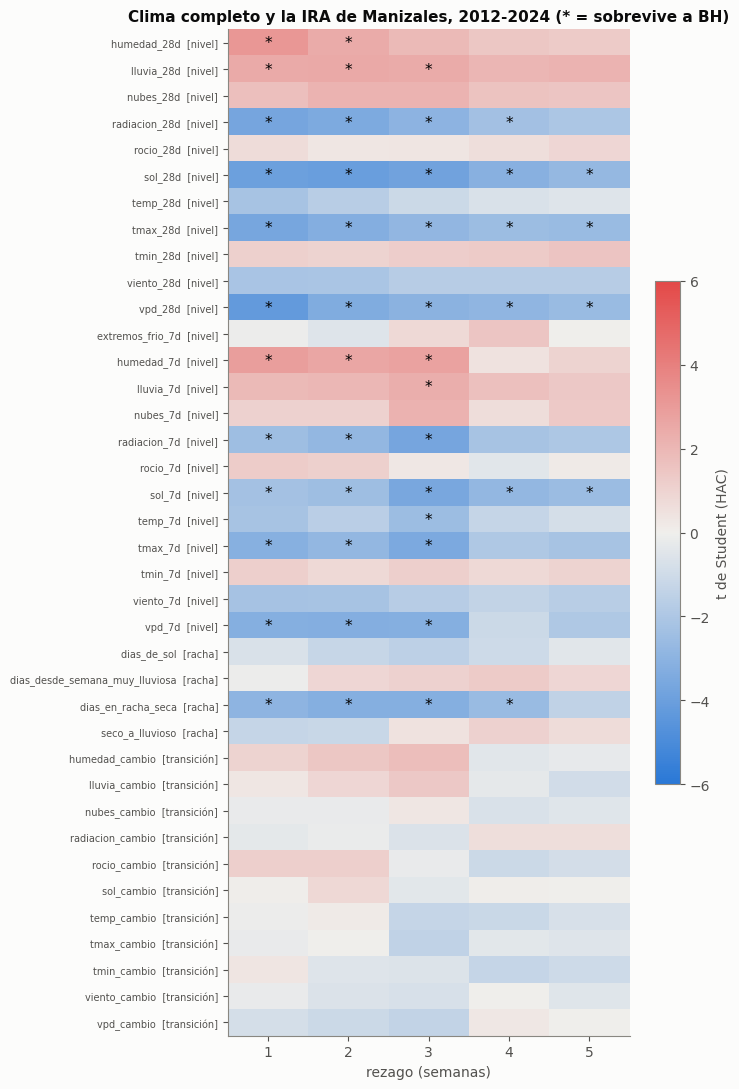

In [33]:
Mt = TI.pivot(index="variable", columns="rezago", values="t").reindex(Xc.columns)
Sv = TI.pivot(index="variable", columns="rezago", values="sobrevive").reindex(Xc.columns)
orden = sorted(Xc.columns, key=lambda c: (FORMA_C(c), c))
fig, ax = plt.subplots(figsize=(7.5, 11))
im = ax.imshow(Mt.loc[orden].values, cmap=DIVERGENTE, vmin=-6, vmax=6, aspect="auto")
for i, c in enumerate(orden):
    for j, k in enumerate(Mt.columns):
        if Sv.loc[c, k]: ax.text(j, i, "*", ha="center", va="center", fontsize=11)
ax.set_xticks(range(5), list(Mt.columns)); ax.set_yticks(range(len(orden)), [f"{c}  [{FORMA_C(c).split(' ')[0]}]" for c in orden], fontsize=7); ax.grid(False)
ax.set_xlabel("rezago (semanas)"); plt.colorbar(im, ax=ax, shrink=.5, label="t de Student (HAC)")
ax.set_title("Clima completo y la IRA de Manizales, 2012-2024 (* = sobrevive a BH)")
plt.tight_layout(); plt.show()

**La IRA de la ciudad sí responde al clima, y esa respuesta no la explica el azar.**

| | Observado | Azar: media (p95) | p empírico |
|---|---|---|---|
| Pruebas con p < 0,05 (de 190) | 63 | 11,0 (26,1) | 0,003 |
| Sobreviven a BH | 47 | 0,75 (4,05) | 0,003 |
| Se confirman en 2025 | 7 | 0,08 (0) | 0,003 |

- **El mecanismo se ve en el desenlace intermedio**, que tiene 13 años y 585 semanas. Es la diferencia con el triage: con el
  mismo método y la misma familia de variables, la señal de la IRA supera por mucho el rango del azar, y la del hospital no.
- **Lo que mueve la IRA es el estado del último mes, no el cambio de la semana.** El 58 % de las pruebas de nivel de 28 días y el
  45 % de las de nivel de 7 días dan p < 0,05 (|t| medio de 2,2 y 1,8), contra **ninguna** de las 55 pruebas de transición (|t|
  medio de 0,6).
- **El signo es el del mecanismo respiratorio:** 38 de las 47 supervivientes son negativas, es decir, menos sol, menos radiación,
  aire menos seco y más lluvia del mes anteceden más IRA. Los mayores efectos son −6,9 % por desviación típica de las horas de sol
  de 28 días a 3 semanas, +6,8 % de la lluvia de 28 días a 1 semana, −6,5 % de la temperatura máxima y −6,3 % del déficit de
  presión de vapor. Coincide con lo que se midió con la misma familia (+6 a +7 % entre 1 y 5 semanas) y con la literatura andina,
  en la que la lluvia se asocia a más virus respiratorios en Bogotá (Rodriguez-Martinez et al., 2015, doi:10.1017/S0950268814003793;
  Gamba-Sanchez et al., 2016, doi:10.1017/S0950268816000273).
- **Se confirman 7 pruebas en 2025**: humedad de 7 y 28 días (+3,1 a +4,6 % en descubrir, hasta +16,8 % en 2025), déficit de
  presión de vapor (−4,3 y −6,3 %), horas de sol y radiación de 7 días (−2,6 y −3,3 %), todas a 1 a 3 semanas. Con 52 semanas el
  intervalo de 2025 es ancho y los efectos mayores que en descubrir no se interpretan como un aumento real.
- **Cautela:** de las pruebas de nivel de 28 días con p < 0,05 en descubrir, solo el 34 % mantiene el signo en 2025. La señal
  existe, pero su forma exacta (qué variable y qué rezago) es inestable; lo que se confirma es la dirección general.

In [34]:
# ---- El puente entre la ciudad y el hospital, por banda de edad: la IRA de Manizales (anomalía operativa) contra el triage
ira_n = ix.anomalia_operativa(np.exp(ira))
ira_n = ira_n / ira_n.loc[:"2024"].std()
XP = pd.DataFrame({"IRA de Manizales (anomalía operativa)": ira_n}).loc["2021-06-01":]
PU_C = ("2025-01-05", "2025-12-28")
EVPU = {n: evaluar(s, XP, range(0, 3), DESC, PU_C, fijo="mes+año", n_sim=200, semilla=8) for n, s in SALIDAS.items()}
filas = []
for n, r in EVPU.items():
    for _, x in r["T"].iterrows():
        filas.append({"desenlace": n, "rezago (sem)": x.rezago, "efecto % por 1 sd (2022-2024)": x["efecto %"], "p": x.p, "efecto % por 1 sd (2025)": x["efecto % conf"], "p (2025)": x.p_conf})
PU = pd.DataFrame(filas)
PU.round({"efecto % por 1 sd (2022-2024)": 1, "p": 4, "efecto % por 1 sd (2025)": 1, "p (2025)": 3})

,desenlace,rezago (sem),efecto % por 1 sd (2022-2024),p,efecto % por 1 sd (2025),p (2025)
0,triage total,0,0.5,0.5873,-0.8,0.657
1,triage total,1,-1.5,0.0857,-0.7,0.620
2,triage total,2,-2.1,0.0042,-1.3,0.242
3,edad 0 a 4 años,0,9.0,0.0008,11.9,0.075
4,edad 0 a 4 años,1,4.6,0.1290,2.2,0.760
5,edad 0 a 4 años,2,1.2,0.7587,-13.5,0.000
6,edad 5 a 14 años,0,6.9,0.0013,10.3,0.139
7,edad 5 a 14 años,1,0.6,0.8296,-0.5,0.936
8,edad 5 a 14 años,2,2.4,0.4718,-13.7,0.005
9,edad 15 a 44 años,0,-0.3,0.8006,-2.2,0.224


**El puente de la ciudad al hospital, por edad, es contemporáneo en los niños y no anticipa a nadie.** Con la IRA de la ciudad
(anomalía operativa, calculable en tiempo real) contra el triage:

- **0 a 4 años:** +9,0 % por desviación típica en la misma semana (p = 0,0008) y +11,9 % en 2025 (p = 0,075). A 1 y 2 semanas, +4,6 % y
  +1,2 %, sin significación.
- **5 a 14 años:** +6,9 % en la misma semana (p = 0,0013) y +10,3 % en 2025 (p = 0,14); a 1 y 2 semanas, +0,6 % y +2,4 %.
- **Egresos respiratorios:** +9,0 % en la misma semana (p = 0,014) y +11,5 % en 2025.
- **Adultos y total:** coeficientes negativos a 1 y 2 semanas (por ejemplo −2,1 % del total a 2 semanas, p = 0,004; −2,9 % de 15 a 44
  años; −3,4 % de 45 a 64), sin una lectura clara.
- **65 años y más:** nada.

De las 21 pruebas, 7 dan p < 0,05 en 2022-2024 y **5 de esas 7 mantienen el signo en 2025**. La lectura es que la ola respiratoria
de la ciudad y la pediatría del hospital suben a la vez: el hospital no recibe a los niños después de la ciudad, los recibe con
ella. Como la IRA de la ciudad se conoce con cerca de una semana de retraso, **no sirve para anticipar la demanda pediátrica de
la misma semana**; a una semana de distancia el efecto es de +4,6 % en 0 a 4 años, sin significación. En 2025 el rezago de 2
semanas invierte el signo en los niños (−13,5 % y −13,7 %), lo que cuestiona cualquier lectura de ese rezago.

Este es el eslabón que se necesitaba entre el clima y el hospital: el clima mueve la IRA de la ciudad (sección 6), y la IRA de la
ciudad se mueve con la pediatría del hospital, pero el clima por sí solo no mueve el triage por banda de forma que se repita.

---
# 7. Episodios concretos

Un promedio de todas las semanas diluye un efecto que ocurre solo después de ciertos episodios. Aquí se miran los episodios por
separado, con dos gatillos fijados antes de mirar el desenlace:

- **Fin de sequía:** las 8 semanas previas (hasta hace 4) al menos un 25 % bajo lo normal en lluvia y las últimas 4 semanas en
  lo normal o por encima. Es la transición que motivó el proyecto. Con la lluvia del consenso hay 4 episodios con triage
  (2022-2026), y con la lluvia de NASA POWER hay más episodios en los 13 años de IRA.
- **Semana muy lluviosa:** lluvia semanal de NASA POWER sobre el percentil 90 de su mes, contando el primer episodio de cada racha.

Para cada episodio se mide el residuo del desenlace (menos su media del mes) de 1 a 4 y de 5 a 8 semanas después. **Prueba de
colocación:** la media de los episodios se compara con la media de igual número de semanas escogidas al azar entre las que no
están a menos de 8 semanas de un episodio (5.000 sorteos). Esa es la vara: no cero, sino lo que se ve en semanas cualesquiera.

In [35]:
# Regla de fin de sequía, fijada antes de mirar el triage: 8 semanas (hasta hace 4) al menos 25 % bajo lo normal y últimas 4 semanas en lo normal o más.
UMBRAL_SECO, UMBRAL_HUMEDO = -25, 0
seco_previo = TEMP["lluvia 8 sem (% sobre lo normal)"].shift(4) <= UMBRAL_SECO
giro = TEMP["lluvia 4 sem (% sobre lo normal)"] >= UMBRAL_HUMEDO
marca = (seco_previo & giro)
inicio = marca & ~marca.shift(1, fill_value=False).rolling(8, min_periods=1).max().astype(bool)
EPIS = list(marca[inicio].index)
print("episodios de fin de sequía 2020-2026 con la lluvia del consenso:", [f"{e:%Y-%m-%d}" for e in EPIS])
print("semanas de 2026 que cumplen la regla:", [f"{e:%Y-%m-%d}" for e in marca[marca].loc["2026"].index])

episodios de fin de sequía 2020-2026 con la lluvia del consenso: ['2020-11-15', '2021-01-17', '2021-06-13', '2021-11-28', '2024-04-21', '2025-10-05', '2026-01-11', '2026-06-28']
semanas de 2026 que cumplen la regla: ['2026-01-11', '2026-01-18', '2026-01-25', '2026-02-01', '2026-06-28', '2026-07-05', '2026-08-16']


In [36]:
# ---- Estudio de eventos con prueba de colocación (placebo): ¿es raro lo que pasó después de estos episodios?
def estudio_eventos(serie, eventos, K=range(-4, 9), ventanas=((1, 4), (5, 8)), excl=2, n_sim=5000, semilla=0):
    """serie: residuo semanal (log). eventos: domingos de inicio. Para cada ventana, la media de los n eventos se compara con la de
    n semanas escogidas al azar entre las que no están a menos de `excl` semanas de ningún episodio."""
    s = serie.reindex(pd.date_range(serie.index.min(), serie.index.max(), freq="7D")); a = s.values
    pos = [s.index.get_loc(e) for e in eventos if e in s.index]
    def stat(p, i, j):
        v = a[p + i: p + j + 1] if p + i >= 0 else np.array([np.nan])
        return np.nanmean(v) if np.isfinite(v).sum() >= max(2, (j - i + 1) // 2) and p + j < len(a) else np.nan
    cerca = np.zeros(len(a), bool)
    for p in pos: cerca[max(0, p - excl): p + excl + 1] = True
    libres = [p for p in range(len(a)) if not cerca[p]]
    rng = np.random.default_rng(semilla); out = {}
    for (i, j) in ventanas:
        por_ev = np.array([stat(p, i, j) for p in pos])
        pl = np.array([stat(p, i, j) for p in libres]); pl = pl[np.isfinite(pl)]
        obs = np.nanmean(por_ev); n = int(np.isfinite(por_ev).sum())
        med = np.array([rng.choice(pl, n).mean() for _ in range(n_sim)])
        out[(i, j)] = {"eventos": n, "efecto %": pct(obs), "por episodio %": pct(por_ev),
                       "p (más que el azar)": (1 + (med >= obs).sum()) / (n_sim + 1), "p (menos que el azar)": (1 + (med <= obs).sum()) / (n_sim + 1),
                       "azar p5-p95 %": (pct(np.quantile(med, .05)), pct(np.quantile(med, .95)))}
    curva = pd.DataFrame({e: [s.get(e + pd.Timedelta(weeks=k), np.nan) for k in K] for e in eventos if e in s.index}, index=list(K))
    return out, curva

def inicios(marca, previo=8):
    """Primera semana de cada racha de semanas marcadas, si no hubo marca en las `previo` semanas anteriores."""
    return list(marca[marca & ~marca.shift(1, fill_value=False).rolling(previo, min_periods=1).max().astype(bool)].index)

def sin_mes(s, ref=None):
    """Residuo menos su media del mes del año (descriptivo: quita la forma del año)."""
    m = (s.index + pd.Timedelta(days=3)).month
    return s - s.groupby(m).transform("mean")

In [37]:
# ---- Episodios de fin de sequía sobre la IRA de la ciudad (13 años; la lluvia de NASA POWER sirve en ventanas de 4 semanas o más)
ccd = ix.clima_diario()
semana_llu = a_semana(ccd.lluvia_nasa, "sum", 6)
semana_llu = semana_llu.reindex(pd.date_range("2010-01-03", "2026-09-27", freq="7D"))
mes_s = pd.Series((semana_llu.index + pd.Timedelta(days=3)).month, index=semana_llu.index)
ref_s = (semana_llu.index >= "2010-01-01") & (semana_llu.index <= "2024-12-31")
def temporada_pct(k):
    ac = semana_llu.rolling(k).sum(); normal = ac[ref_s].groupby(mes_s[ref_s]).mean()
    return 100 * (ac / normal.reindex(mes_s.values).values - 1)
T4, T8 = temporada_pct(4), temporada_pct(8)
marca_n = (T8.shift(4) <= UMBRAL_SECO) & (T4 >= UMBRAL_HUMEDO)
EP_N = inicios(marca_n)
EP_N_IRA = [e for e in EP_N if ira.loc[e - pd.Timedelta(weeks=4): e + pd.Timedelta(weeks=8)].notna().sum() >= 10]
print(f"fines de sequía 2010-2026 con la lluvia de NASA POWER: {len(EP_N)}; con IRA observada alrededor: {len(EP_N_IRA)}")
Zf = np.column_stack([pd.get_dummies(pd.Index((ira.index + pd.Timedelta(days=3)).month), drop_first=True).values.astype(float),
                      pd.get_dummies(pd.Index((ira.index + pd.Timedelta(days=3)).year), drop_first=True).values.astype(float)])
def resid_fe(s):
    ok = s.notna().values; Z = np.column_stack([np.ones(ok.sum()), Zf[ok][:, Zf[ok].any(axis=0)]])
    r = pd.Series(np.nan, index=s.index); r[ok] = s[ok].values - Z @ np.linalg.lstsq(Z, s[ok].values, rcond=None)[0]; return r
ira_r = resid_fe(ira.loc["2012-01-01":"2025-12-28"])
EVIRA, CURVA_IRA = estudio_eventos(ira_r, EP_N_IRA)
# semana muy lluviosa: lluvia semanal de NASA POWER sobre el percentil 90 de su mes; se cuenta el primer episodio de cada racha
flag = (semana_llu > semana_llu[ref_s].groupby(mes_s[ref_s]).quantile(.9).reindex(mes_s.values).values) & semana_llu.notna()
EP_LL = inicios(flag, 3)
EP_LL_IRA = [e for e in EP_LL if ira.loc[e - pd.Timedelta(weeks=4): e + pd.Timedelta(weeks=8)].notna().sum() >= 10 and e <= pd.Timestamp("2025-12-28")]
EVIRA2, CURVA_IRA2 = estudio_eventos(ira_r, EP_LL_IRA)
print(f"semanas muy lluviosas (inicio de racha) con IRA observada alrededor: {len(EP_LL_IRA)}")
filas = []
for gat, r_ in [("fin de sequía", EVIRA), ("semana muy lluviosa", EVIRA2)]:
    for (a_, b_), x in r_.items():
        filas.append({"gatillo": gat, "ventana": f"{a_} a {b_} semanas", "episodios": x["eventos"], "efecto % sobre la IRA": x["efecto %"], "azar p5": x["azar p5-p95 %"][0], "azar p95": x["azar p5-p95 %"][1], "p (más)": x["p (más que el azar)"], "p (menos)": x["p (menos que el azar)"]})
display(pd.DataFrame(filas).round(2))

fines de sequía 2010-2026 con la lluvia de NASA POWER: 22; con IRA observada alrededor: 13


semanas muy lluviosas (inicio de racha) con IRA observada alrededor: 44


,gatillo,ventana,episodios,efecto % sobre la IRA,azar p5,azar p95,p (más),p (menos)
0,fin de sequía,1 a 4 semanas,13,-3.89,-11.91,9.82,0.79,0.21
1,fin de sequía,5 a 8 semanas,13,-2.92,-11.17,9.98,0.77,0.23
2,semana muy lluviosa,1 a 4 semanas,44,4.64,-7.78,4.07,0.03,0.97
3,semana muy lluviosa,5 a 8 semanas,44,0.96,-7.37,5.28,0.37,0.63


In [38]:
# ---- Episodios sobre el triage, por banda de edad
EP_LL_T = [e for e in EP_LL if pd.Timestamp("2022-03-06") <= e <= pd.Timestamp("2026-08-23")]
EP_SEQ_T = [e for e in EPIS if e >= pd.Timestamp("2022-03-06")]
print(f"semanas muy lluviosas (inicio de racha) con triage 2022-03 a 2026-08: {len(EP_LL_T)}; fines de sequía con triage: {len(EP_SEQ_T)} {[f'{e:%Y-%m-%d}' for e in EP_SEQ_T]}")
filas, DET = [], {}
for gat, eps in [("fin de sequía", EP_SEQ_T), ("semana muy lluviosa", EP_LL_T)]:
    for nombre, s in SALIDAS.items():
        r, curva = estudio_eventos(sin_mes(s), eps)
        DET[(gat, nombre)] = (r, curva)
        for v_, (a_, b_) in zip(("1 a 4 semanas", "5 a 8 semanas"), r):
            x = r[(a_, b_)]
            filas.append({"gatillo": gat, "desenlace": nombre, "ventana": v_, "episodios": x["eventos"], "efecto %": x["efecto %"], "azar p5": x["azar p5-p95 %"][0], "azar p95": x["azar p5-p95 %"][1], "p (más)": x["p (más que el azar)"], "p (menos)": x["p (menos que el azar)"]})
EPT = pd.DataFrame(filas)
EPT.round(2)

semanas muy lluviosas (inicio de racha) con triage 2022-03 a 2026-08: 17; fines de sequía con triage: 4 ['2024-04-21', '2025-10-05', '2026-01-11', '2026-06-28']


,gatillo,desenlace,ventana,episodios,efecto %,azar p5,azar p95,p (más),p (menos)
0,fin de sequía,triage total,1 a 4 semanas,4,0.12,-2.56,2.70,0.47,0.53
1,fin de sequía,triage total,5 a 8 semanas,4,-1.09,-2.48,2.67,0.76,0.24
2,fin de sequía,edad 0 a 4 años,1 a 4 semanas,4,-4.30,-9.90,11.12,0.76,0.25
3,fin de sequía,edad 0 a 4 años,5 a 8 semanas,4,-1.16,-10.34,11.06,0.58,0.42
4,fin de sequía,edad 5 a 14 años,1 a 4 semanas,4,-3.46,-9.82,11.87,0.73,0.27
5,fin de sequía,edad 5 a 14 años,5 a 8 semanas,4,0.62,-9.99,11.62,0.49,0.51
6,fin de sequía,edad 15 a 44 años,1 a 4 semanas,4,0.43,-2.88,3.12,0.40,0.60
7,fin de sequía,edad 15 a 44 años,5 a 8 semanas,4,-1.91,-2.74,3.10,0.88,0.12
8,fin de sequía,edad 45 a 64 años,1 a 4 semanas,4,0.94,-3.88,3.64,0.32,0.68
9,fin de sequía,edad 45 a 64 años,5 a 8 semanas,4,-0.15,-3.96,3.73,0.50,0.50


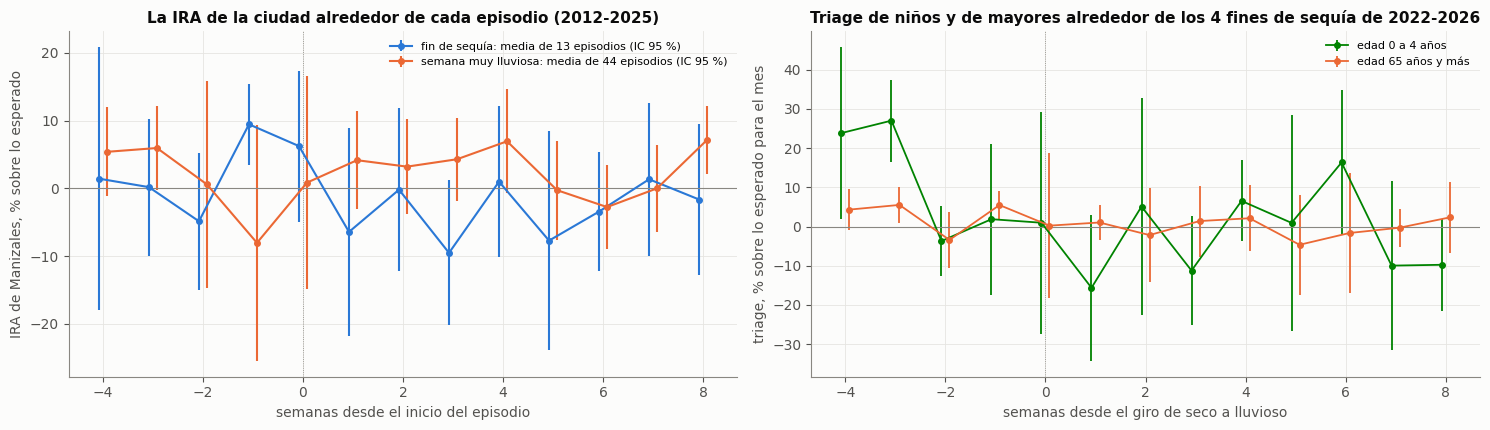

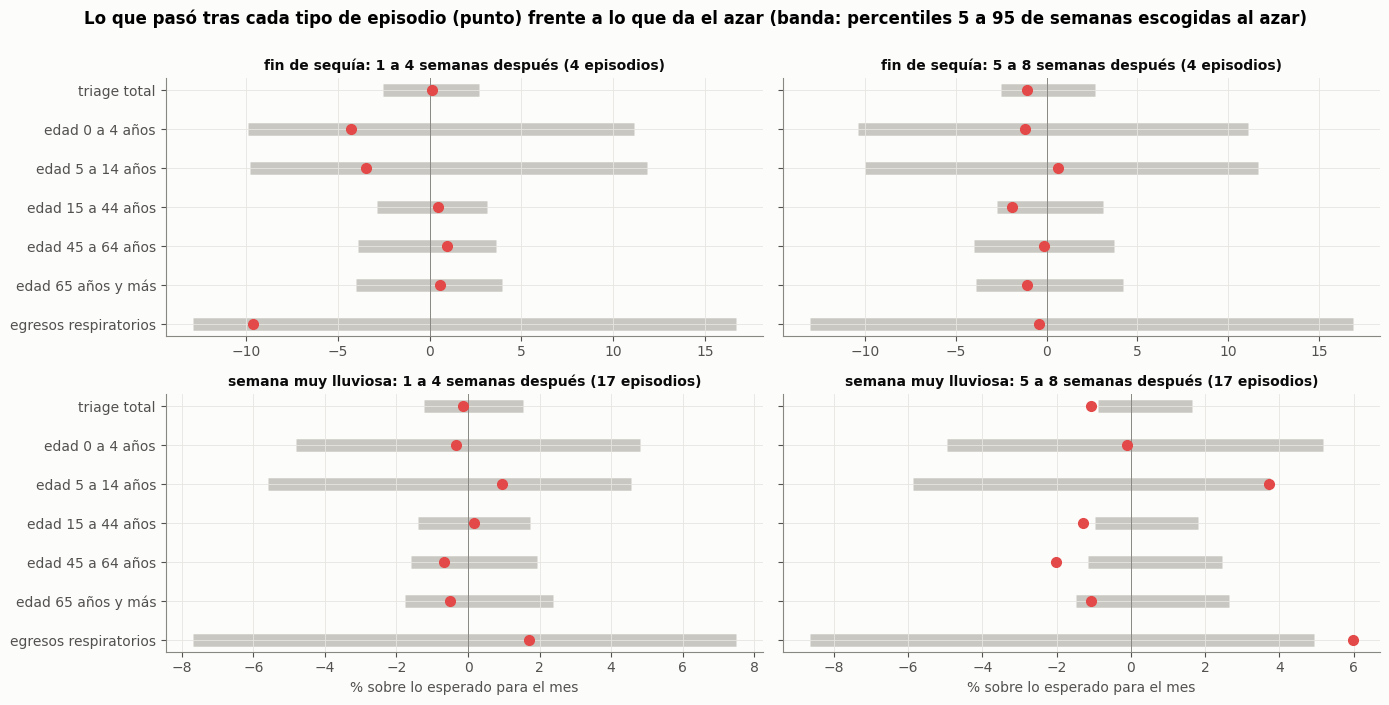

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
ax = axes[0]; K = list(CURVA_IRA.index)
for cur, col, nom, dx in [(CURVA_IRA, AZUL, "fin de sequía", -.08), (CURVA_IRA2, NARANJA, "semana muy lluviosa", .08)]:
    m_ = cur.mean(axis=1); e_ = 1.96 * cur.std(axis=1) / np.sqrt(cur.notna().sum(axis=1))
    ax.errorbar(np.array(K) + dx, pct(m_), yerr=100 * e_, fmt="o-", color=col, ms=4, lw=1.5, label=f"{nom}: media de {cur.shape[1]} episodios (IC 95 %)")
ax.axhline(0, color=MUDO, lw=.8); ax.axvline(0, color=MUDO, lw=.6, ls=":"); ax.legend(fontsize=8)
ax.set_xlabel("semanas desde el inicio del episodio"); ax.set_ylabel("IRA de Manizales, % sobre lo esperado")
ax.set_title("La IRA de la ciudad alrededor de cada episodio (2012-2025)")
ax = axes[1]
for (gat, nombre), (r, curva) in DET.items():
    if nombre in ("edad 0 a 4 años", "edad 65 años y más") and gat == "fin de sequía":
        mm = curva.mean(axis=1); ee = 1.96 * curva.std(axis=1) / np.sqrt(curva.notna().sum(axis=1))
        ax.errorbar(np.array(K) + (.08 if "65" in nombre else -.08), pct(mm), yerr=100 * ee, fmt="o-", ms=4, lw=1.3, color=NARANJA if "65" in nombre else VERDE, label=nombre)
ax.axhline(0, color=MUDO, lw=.8); ax.axvline(0, color=MUDO, lw=.6, ls=":"); ax.legend(fontsize=8)
ax.set_xlabel("semanas desde el giro de seco a lluvioso"); ax.set_ylabel("triage, % sobre lo esperado para el mes")
ax.set_title(f"Triage de niños y de mayores alrededor de los {len(EP_SEQ_T)} fines de sequía de 2022-2026")
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=False)
nombres = list(SALIDAS)
for i, gat in enumerate(["fin de sequía", "semana muy lluviosa"]):
    for j, v_ in enumerate(["1 a 4 semanas", "5 a 8 semanas"]):
        ax = axes[i, j]; q = EPT[(EPT.gatillo == gat) & (EPT.ventana == v_)].set_index("desenlace").reindex(nombres)
        yy = np.arange(len(nombres))[::-1]
        ax.hlines(yy, q["azar p5"], q["azar p95"], color="#c9c7c1", lw=9, zorder=1); ax.plot(q["efecto %"], yy, "o", color=ROJO, ms=7, zorder=3)
        ax.axvline(0, color=MUDO, lw=.7); ax.set_yticks(yy, nombres if j == 0 else [""] * len(nombres))
        ax.set_title(f"{gat}: {v_} después ({int(q.episodios.max())} episodios)", fontsize=10)
        if i == 1: ax.set_xlabel("% sobre lo esperado para el mes")
fig.suptitle("Lo que pasó tras cada tipo de episodio (punto) frente a lo que da el azar (banda: percentiles 5 a 95 de semanas escogidas al azar)", fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

**Los episodios dicen lo mismo que los promedios, con una excepción pequeña.**

La primera figura muestra, a la izquierda, la IRA de la ciudad alrededor de cada tipo de episodio, con intervalos que cruzan el cero en casi todas las semanas, y a la derecha el triage de niños y mayores alrededor de los fines de sequía, con intervalos muy anchos porque son solo cuatro episodios. La segunda compara el resultado de cada episodio con el rango que dan semanas escogidas al azar (banda gris): lo que cuenta es que el punto quede fuera de la banda.

*Fin de sequía.*
- **IRA de la ciudad, 13 episodios (2012-2025):** −3,9 % a 1 a 4 semanas y −2,9 % a 5 a 8 semanas, con el azar entre −11,9 y +9,8 %.
  **No hay ola de IRA después de la sequía.**
- **Triage, 4 episodios (2024-04-21, 2025-10-05, 2026-01-11 y 2026-06-28):** el total queda en +0,1 % y −1,1 %, con el azar entre
  −2,6 y +2,7 %; ninguna banda sale de su rango. Con cuatro episodios, y uno de ellos (2026-06-28) solapado con la sequía actual,
  esto es anecdótico: los intervalos del azar de las bandas pediátricas son de ±10 %.

*Semana muy lluviosa.*
- **IRA de la ciudad, 44 episodios:** +4,6 % a 1 a 4 semanas, justo por encima del percentil 95 del azar (+4,1 %; p = 0,03), y +1,0 % a
  5 a 8 semanas. Es la única señal episódica del desenlace intermedio, pequeña y borderline, y encaja con el efecto de la lluvia
  del último mes sobre la IRA de la sección 6.
- **Triage, 17 episodios:** a 1 a 4 semanas no se sale nada del rango del azar. A 5 a 8 semanas hay cinco comparaciones en la cola del
  5 %: el total (−1,1 %), los adultos de 15 a 44 (−1,3 %) y de 45 a 64 años (−2,0 %) quedan **por debajo** y los niños de 5 a 14
  años (+3,7 %) y los egresos respiratorios (+6,0 %), **por encima**. La dirección (más demanda pediátrica y respiratoria,
  menos de adultos) concuerda con la de las secciones anteriores, pero son 5 de 28 comparaciones sin corrección por pruebas
  múltiples y con episodios que se solapan en la estación, así que se leen como una hipótesis para un periodo más largo, no como un
  hallazgo.

En conjunto, la transición que motivó el proyecto, el paso de la sequía a la lluvia, **no deja una ola medible en la IRA ni
en el triage**. Lo que deja huella en la IRA es la lluvia fuerte del último mes.

---
# 8. El estado de hoy

Primero, las últimas semanas con clima completo en los índices y en la temporada del consenso, y la lluvia mensual del último
año contra lo normal, con dos controles: la lluvia de NASA sin escalar (independiente del pluviómetro) y el porcentaje de días
con pluviómetro válido. Después, el clima completo hasta fines de septiembre y el triage de las últimas semanas. **Es
descriptivo, no un pronóstico.**

In [40]:
ACT = pd.concat([IDX, TEMP.round(0), anom["temp. media"].rename("temp. media, anomalía (°C)"),
                 nivel["racha seca"].rename("racha seca al cierre (días)")], axis=1).loc["2026-05-03":"2026-08-23"].round(2)
ACT.index = ACT.index.strftime("%Y-%m-%d"); ACT.index.name = "semana que empieza"
print("rango de cada índice en descubrir (sd):", {c: (round(IDX[c].loc[DESC[0]:DESC[1]].min(), 2), round(IDX[c].loc[DESC[0]:DESC[1]].max(), 2)) for c in IDX})
print("racha seca al cierre de semana, máximo en descubrir:", nivel["racha seca"].loc[DESC[0]:DESC[1]].max(), "días")
display(ACT)
mm = diarias.lluvia.loc["2025-09-01":"2026-08-28"].resample("MS").sum()
normal_mes = diarias.lluvia.loc[CLIMA_REF[0]:CLIMA_REF[1]]; normal_mes = normal_mes.groupby(normal_mes.index.month).mean()
fuente = (dia.precip_con_estacion & ~dia.pluviometro_fallido).loc["2025-09-01":"2026-08-28"].resample("MS").mean()
nasa_mm = dia.np_PRECTOTCORR.loc["2025-09-01":"2026-08-28"].resample("MS").sum()          # control independiente del pluviómetro
nasa_ref = dia.np_PRECTOTCORR.loc[CLIMA_REF[0]:CLIMA_REF[1]]; nasa_ref = nasa_ref.groupby(nasa_ref.index.month).mean()
pd.DataFrame({"lluvia (mm)": mm.round(0), "NASA sin escalar, % sobre su propia normal":
              (100 * (nasa_mm / (nasa_ref.reindex(nasa_mm.index.month).values * nasa_mm.index.days_in_month) - 1)).round(0),"normal (mm)": (normal_mes.reindex(mm.index.month).values * mm.index.days_in_month).round(0),
              "% sobre lo normal": (100 * (mm / (normal_mes.reindex(mm.index.month).values * mm.index.days_in_month) - 1)).round(0),
              "% días con pluviómetro": (100 * fuente).round(0)}).set_axis(mm.index.strftime("%Y-%m")).T

rango de cada índice en descubrir (sd): {'CP1 soleado y seco': (-2.2, 3.02), 'CP2 bochorno húmedo': (-3.63, 2.4), 'CP3 racha seca en calma': (-2.08, 4.96), 'CP4 ventoso': (-2.18, 2.88)}
racha seca al cierre de semana, máximo en descubrir: 15.0 días


,CP1 soleado y seco,CP2 bochorno húmedo,CP3 racha seca en calma,CP4 ventoso,lluvia 4 sem (% sobre lo normal),lluvia 8 sem (% sobre lo normal),giro 4 sem (pp),giro 8 sem (pp),"temp. media, anomalía (°C)",racha seca al cierre (días)
semana que empieza,,,,,,,,,,
2026-05-03,0.66,-0.39,0.60,-1.62,-28.0,-28.0,1.0,-42.0,0.35,1.0
2026-05-10,0.42,-0.10,1.11,-2.17,-45.0,-29.0,-28.0,-43.0,0.44,1.0
2026-05-17,0.40,-0.35,0.42,-2.35,-52.0,-39.0,-22.0,-55.0,0.39,0.0
2026-05-24,-0.13,0.86,1.49,-2.61,-46.0,-43.0,-5.0,-28.0,0.56,0.0
2026-05-31,-0.09,1.07,1.25,-1.93,-58.0,-43.0,-29.0,-26.0,0.53,0.0
2026-06-07,0.48,0.25,0.63,-1.70,-50.0,-47.0,-6.0,-34.0,0.44,0.0
2026-06-14,0.31,-0.12,0.71,-1.41,-28.0,-39.0,24.0,-23.0,0.34,0.0
2026-06-21,1.19,0.58,0.79,0.69,-2.0,-22.0,44.0,5.0,1.14,2.0
2026-06-28,-0.26,1.32,1.40,-2.00,24.0,-22.0,82.0,6.0,0.78,0.0


fecha,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
lluvia (mm),57.0,146.0,69.0,46.0,187.0,91.0,153.0,81.0,68.0,129.0,55.0,111.0
"NASA sin escalar, % sobre su propia normal",40.0,17.0,-28.0,-29.0,125.0,50.0,-8.0,-35.0,-44.0,-19.0,-49.0,28.0
normal (mm),54.0,139.0,97.0,81.0,80.0,62.0,176.0,126.0,123.0,158.0,115.0,77.0
% sobre lo normal,7.0,5.0,-29.0,-42.0,132.0,46.0,-13.0,-35.0,-45.0,-19.0,-52.0,44.0
% días con pluviómetro,90.0,35.0,100.0,100.0,16.0,0.0,0.0,0.0,0.0,0.0,52.0,43.0


In [41]:
# Las dos versiones de la lluvia de NASA POWER en 2026 no coinciden desde el 1 de agosto
cmp_ = pd.DataFrame({"clima completo": ix.clima_diario().lluvia_nasa, "clima unificado (NASA)": cl.np_PRECTOTCORR, "consenso": cl.precip_consenso_mm}).loc["2026-07-01":"2026-08-24"]
tabla_cmp = pd.DataFrame({"julio (mm)": cmp_.loc["2026-07"].sum(), "1 a 24 de agosto (mm)": cmp_.loc["2026-08-01":"2026-08-24"].sum(),
                          "días de agosto distintos del clima completo": [np.nan, (cmp_["clima unificado (NASA)"].loc["2026-08"] - cmp_["clima completo"].loc["2026-08"]).abs().gt(.05).sum(), np.nan]}).round(1)
dd = pd.DataFrame({"pluviómetro válido": (cl.precip_con_estacion & ~cl.pluviometro_fallido).loc["2026-08-12":"2026-08-17"],
                   "consenso (mm)": cl.precip_consenso_mm.loc["2026-08-12":"2026-08-17"], "clima completo (mm)": ix.clima_diario().lluvia_nasa.loc["2026-08-12":"2026-08-17"],
                   "clima unificado, NASA (mm)": cl.np_PRECTOTCORR.loc["2026-08-12":"2026-08-17"]}).round(1)
print("los dos archivos coinciden hasta el 2026-07-31; desde el 2026-08-01 el clima completo trae mucha menos lluvia. Días de agosto con pluviómetro válido y lo que marcan:")
display(tabla_cmp.T); display(dd)
# El estado de las últimas semanas: clima completo (sin la lluvia) y triage
hoy = pd.DataFrame({"lluvia 4 sem, consenso (% sobre lo normal)": TEMP["lluvia 4 sem (% sobre lo normal)"], "lluvia 8 sem, consenso (% sobre lo normal)": TEMP["lluvia 8 sem (% sobre lo normal)"],
                    "temp. media, cambio (sd)": Xc["temp_cambio"], "horas de sol, 28 d (sd)": Xc["sol_28d"], "nubosidad, 28 d (sd)": Xc["nubes_28d"]}).loc["2026-07-05":"2026-09-20"].round(1)
for n in ["triage total", "edad 0 a 4 años", "edad 65 años y más"]:
    hoy[f"{n} (% sobre lo esperado)"] = pct(sin_mes(SALIDAS[n].loc["2022-03-06":])).reindex(hoy.index).round(1)
hoy.index = hoy.index.strftime("%Y-%m-%d"); hoy.index.name = "semana que empieza"
print("horas de sol de 28 días: mínimo en 2012-2024 =", round(Xc["sol_28d"].loc["2012-01-01":"2024-12-31"].min(), 2), "sd; semana del 2026-08-30 =", round(Xc["sol_28d"].loc["2026-08-30"], 2), "sd")
hoy

los dos archivos coinciden hasta el 2026-07-31; desde el 2026-08-01 el clima completo trae mucha menos lluvia. Días de agosto con pluviómetro válido y lo que marcan:


,clima completo,clima unificado (NASA),consenso
julio (mm),72.6,72.6,55.2
1 a 24 de agosto (mm),49.7,154.3,111.1
días de agosto distintos del clima completo,NaN,24.0,NaN


,pluviómetro válido,consenso (mm),clima completo (mm),"clima unificado, NASA (mm)"
fecha,,,,
2026-08-12,True,0.3,1.8,0.9
2026-08-13,True,0.5,1.4,1.5
2026-08-14,True,2.0,1.8,6.4
2026-08-15,True,1.9,1.4,6.0
2026-08-16,True,10.6,14.2,11.6
2026-08-17,True,41.6,18.1,32.9


horas de sol de 28 días: mínimo en 2012-2024 = -3.1 sd; semana del 2026-08-30 = -3.8 sd


,"lluvia 4 sem, consenso (% sobre lo normal)","lluvia 8 sem, consenso (% sobre lo normal)","temp. media, cambio (sd)","horas de sol, 28 d (sd)","nubosidad, 28 d (sd)",triage total (% sobre lo esperado),edad 0 a 4 años (% sobre lo esperado),edad 65 años y más (% sobre lo esperado)
semana que empieza,,,,,,,,
2026-07-05,8.6,-25.4,1.9,-1.6,-0.1,0.1,2.0,-4.3
2026-07-12,-20.1,-27.4,0.5,-1.9,0.2,-4.1,46.5,-11.7
2026-07-19,-55.8,-30.8,-0.9,-3.1,0.7,3.5,6.8,-11.7
2026-07-26,-80.4,-34.0,-1.3,-2.8,0.7,-4.0,19.0,-5.6
2026-08-02,-42.0,-9.0,1.7,-3.2,1.0,-1.7,-3.8,5.3
2026-08-09,-32.9,-22.6,2.1,-2.8,0.4,-20.4,-9.3,-22.0
2026-08-16,29.9,-17.4,1.3,-3.0,0.4,-7.2,-12.6,-4.9
2026-08-23,NaN,NaN,1.1,-4.2,0.8,1.7,-14.6,0.1
2026-08-30,NaN,NaN,0.4,-3.8,0.7,5.9,-17.2,11.1


**Dos versiones de la lluvia de NASA POWER no coinciden desde el 1 de agosto de 2026.** Los dos archivos son idénticos hasta el
2026-07-31 (72,6 mm en julio en ambos). Entre el 1 y el 24 de agosto, el clima completo suma 49,7 mm, el clima unificado 154,3 mm
y el consenso 111,1 mm. En los días de agosto con pluviómetro válido, el 17 el consenso marca 41,6 mm, el clima
unificado 32,9 y el clima completo 18,1. Es probable que la serie del clima completo para agosto y septiembre sea provisional y
subestime la lluvia, y por eso la sección usa el consenso para la temporada. Qué versión es la correcta no se puede decidir con estos
datos.

**La sequía de 2026 fue real y terminó entre mediados de agosto y comienzos de septiembre**, según la fuente:
- Con el consenso, la lluvia de 4 semanas pasa de −80 % (semana del 2026-07-26) a +30 % (semana del 2026-08-16), un giro de +86
  puntos, y esa semana cumple la regla de fin de sequía; la del 2026-06-28 fue una falsa salida.
- Con el clima completo, la lluvia diaria solo se normaliza desde el 2026-09-01 y se intensifica del 25 al 28 de septiembre.
- Julio fue el mes más seco de 2026 (−52 % del consenso), con una racha de 14 días sin lluvia al cierre de la semana del
  2026-07-12 (el máximo en descubrir fue 15) y CP3 en 7,17 sd, por encima de su máximo en descubrir (4,96).
- Entre marzo y junio no hubo un solo día de pluviómetro válido, pero NASA sin escalar da la misma sequía (−44 % en mayo), así que
  no es la sequía falsa que fabricaba el pluviómetro roto.

**El estado de las últimas semanas es de cielo cubierto.** Las horas de sol de 28 días llegan a −4,2 sd la semana del 2026-08-23 y a
−3,8 sd la del 2026-08-30, por debajo del mínimo de 2012-2024 (−3,1 sd), con nubosidad de +0,7 a +1,1 sd. Es el estado en el que, en
la IRA de 2012-2024, el sol del último mes anticipa más enfermedad respiratoria; pero esa relación se mantiene en 2025 por otras
variables, no por esta (en 2025 las horas de sol de 28 días a 3 semanas dan +4,8 %, con el signo contrario), y el estado actual
queda fuera del rango con que se estimó. El triage de las tres últimas semanas con dato queda por encima de lo esperado para el mes:
+5,9 %, +9,3 % y +13,7 % en el total, y +11,1 %, +14,9 % y +14,1 % en los mayores de 65 años; los niños de 0 a 4 años bajan 17 % y
suben 12 % y 7 %. Son tres semanas y no hay IRA de 2026 en este cuaderno. Es una descripción, no una predicción.

---
# 9. Balance, conclusiones y límites del análisis

In [42]:
# ---- Balance: lo observado frente a lo que da el azar, en todas las familias de pruebas del cuaderno
filas = []
def anotar(familia, nombre, r):
    s = r["resumen"]
    filas.append({"familia de pruebas": familia, "desenlace": nombre, "pruebas": s["pruebas"], "sobreviven a BH": s["sobreviven BH"], "azar (media)": round(s["BH azar (media)"], 1),
                  "p empírico": round(s["p emp. BH"], 2), "se confirman": s["se confirman"], "azar (media) ": round(s["conf. azar (media)"], 2), "r(t desc., t conf.)": round(s["r(t desc., t conf.)"], 2), "p inversión de r": round(s["p emp. r (inversión)"], 3)})
anotar("consenso, 0 a 8 semanas, sin mes fijo (barrido original)", "triage total", EVA)
for n, r in EV.items(): anotar("consenso, 1 a 5 semanas, mes y año fijos", n, r)
for n, r in EVC.items(): anotar("clima completo, 1 a 5 semanas, mes y año fijos", n, r)
anotar("clima completo, 0 a 6 semanas, mes y año fijos", "triage total", EVC0)
for n, r in EV21.items(): anotar("9 índices del clima completo, 1 a 5 semanas", n, r)
for n, r in EVP.items(): anotar("4 estados del clima (componentes), 1 a 5 semanas", n, r)
anotar("clima completo, 1 a 5 semanas, mes y año fijos", "IRA de Manizales (2012-2024; confirma 2025)", EVI)
BAL = pd.DataFrame(filas)
tri = BAL[~BAL["desenlace"].str.startswith("IRA")]
print(f"de {len(tri)} pruebas de familia sobre el triage y los egresos, {int((tri['p empírico'] <= .10).sum())} tienen un p empírico <= 0,10 en el número de supervivientes (con p uniforme se esperarían ~{.1*len(tri):.0f}; las filas se solapan y no son independientes), "
      f"y {int((tri['p inversión de r'] <= .05).sum())} tienen una inversión de r con p <= 0,05")
BAL.set_index(["familia de pruebas", "desenlace"])

de 30 pruebas de familia sobre el triage y los egresos, 8 tienen un p empírico <= 0,10 en el número de supervivientes (con p uniforme se esperarían ~3; las filas se solapan y no son independientes), y 5 tienen una inversión de r con p <= 0,05


pruebas  sobreviven a BH  azar (media)  p empírico  se confirman  azar (media)   r(t desc., t conf.)  p inversión de r
familia de pruebas                                 desenlace                                                                                                                                                          
consenso, 0 a 8 semanas, sin mes fijo (barrido ... triage total                                     693               34          15.5        0.12             1           1.05                -0.01             0.485
consenso, 1 a 5 semanas, mes y año fijos           triage total                                     385                6           7.3        0.33             0           0.53                -0.20             0.150
                                                   edad 0 a 4 años                                  385               17           5.3        0.08             1           0.52                 0.17             0.777
                                                   edad 5 a 14 años                                 385               58          14.3        0.08             2           1.28                 0.13             0.691
                                                   edad 15 a 44 años                                385               25           6.5        0.09             0           0.33                -0.14             0.236
                                                   edad 45 a 64 años                                385                3           9.0        0.52             0           0.60                -0.04             0.415
                                                   edad 65 años y más                               385                0          14.0        1.00             0           0.81                -0.32             0.053
                                                   egresos respiratorios                            385                0           6.3        1.00             0           0.68                 0.13             0.701
clima completo, 1 a 5 semanas, mes y año fijos     triage total                                     190                4           8.9        0.34             0           0.84                -0.54             0.010
                                                   edad 0 a 4 años                                  190               24           6.8        0.06             2           0.87                 0.36             0.854
                                                   edad 5 a 14 años                                 190               44          11.2        0.06             0           1.65                -0.03             0.475
                                                   edad 15 a 44 años                                190               27           6.3        0.07             0           0.53                -0.42             0.043
                                                   edad 45 a 64 años                                190               23          11.9        0.26             0           0.58                -0.25             0.186
                                                   edad 65 años y más                               190                5          14.0        0.50             0           1.33                -0.23             0.236
                                                   egresos respiratorios                            190                0           8.4        1.00             0           1.02                 0.04             0.518
clima completo, 0 a 6 semanas, mes y año fijos     triage total                                     266               18          12.7        0.24             0           1.27                -0.53             0.027
9 índices del clima completo, 1 a 5 semanas        triage total                                      45                5           1.7        0.15             0           0.11                -0.43             0.043
           

La tabla pone, para cada familia de pruebas del cuaderno, lo observado frente a lo que da el azar con la misma estructura. La
cuenta de arriba resume cuántas de las familias del triage tienen un número de supervivientes con p empírico de 0,10 o menos.
Esas filas se solapan (las mismas semanas y variables parecidas), de modo que no son independientes y el recuento sirve como
descripción, no como prueba.

---
## Conclusiones

1. **Lo que se había concluido cambia de forma.** El barrido original del triage total, de 693 pruebas, daba 84 con p < 0,05 y 34
   supervivientes frente a 66,7 y 15,5 que da el azar con la estructura real (p empírico 0,15 y 0,12). El resultado era compatible
   con la ausencia de relación, y también con una relación pequeña. Ese diseño no podía distinguirlas, y la conclusión «el clima no
   predice el triage» no estaba sostenida; tampoco lo está su contraria.
2. **Con el reloj del mecanismo y por banda de edad, nada supera al azar a un nivel convencional.** En las bandas de 0 a 4, 5 a
   14 y 15 a 44 años el número de supervivientes queda cerca del borde (p empírico de 0,06 a 0,09, con el consenso y con el clima
   completo), pero en 2025-2026 se confirman 0 a 2 pruebas por banda y la correlación del patrón entre periodos no supera al azar.
   Para el total y los adultos el patrón de 2022-2024 **se invierte** en 2025-2026 (r = −0,54 en el total con el clima completo; solo
   2 de 300 desplazamientos igualan esa inversión, p = 0,010). La excepción es de dirección y no de significación: el estado soleado y
   seco anticipa **menos** triage en los niños de 0 a 4 y de 5 a 14 años a 1 a 5 semanas, con diez coeficientes negativos en 2022-2024 y
   nueve de diez en 2025-2026.
3. **La transición medida como cambio semanal no tiene señal; el nivel del último mes sí.** Las pruebas de transición dan p < 0,05
   en el 3,1 % de los casos (nivel: 20,8 %), y sobre la IRA, ninguna de 55. El paso de la sequía a la lluvia no deja una ola medible,
   ni en la IRA (13 episodios) ni en el triage (4 episodios).
4. **El desenlace intermedio sí responde.** La IRA de Manizales tiene 47 pruebas supervivientes de 190, contra 0,75 del azar, y
   7 se confirman en 2025, contra 0,08. Menos sol, más humedad y más lluvia en el último mes anteceden más IRA a 1 a 3 semanas, y
   las lluvias fuertes dejan +4,6 % en las 4 semanas posteriores.
5. **La IRA de la ciudad y la pediatría del hospital suben a la vez** (+9,0 % y +6,9 % por desviación típica en la misma semana,
   sin rezago), de modo que la IRA de la ciudad no anticipa la demanda pediátrica.
6. **Coherencia con lo hallado antes.** Los 36 supervivientes del triage total del cuaderno 17 pasan a 18 al asignar el mes a la mitad
   de la semana, y el azar da 12,7. La asociación de los mayores con la lluvia reciente (+4,6 % en el cuaderno 21) se reproduce
   en 2022-2024 (−5,0 a −5,4 % de los días desde la última semana muy lluviosa, a 1 a 3 semanas, sobre el límite del azar), pero se
   invierte en 2025-2026 (+4,2 %). El efecto de +6 a +7 % de la IRA se confirma. Lo que difiere es la lectura: antes se contaban
   los supervivientes sin descontar el azar de esta estructura.

---
## Qué puede sostenerse y qué no

| Pieza | Estado | Por qué |
|---|---|---|
| Clima del último mes (humedad, déficit de presión de vapor, sol) → IRA de la ciudad a 1 a 3 semanas | **Sostenida** | 47 supervivientes contra 0,75 del azar; 7 confirmadas en 2025 |
| Lluvia fuerte → +4,6 % de IRA en 4 semanas | Sostenida con cautela | 44 episodios, justo sobre el p95 del azar (p = 0,03) |
| IRA de la ciudad ↔ pediatría del hospital, misma semana | Sostenida con cautela | +9,0 % y +6,9 % por sd; mismo signo en 2025, sin significación |
| Cambio de radiación a 2 semanas → triage total | **No se sostiene** | Se confirma 1 de 34, lo que da el azar (1,05) |
| Estado soleado y seco → menos triage en niños de 0 a 14 años | Hipótesis de dirección | 10 de 10 coeficientes negativos en descubrir y 9 de 10 en confirmar; solo 1 prueba con p < 0,05 en confirmar |
| Estados del clima → triage de adultos y total | No predictor | 0 confirmaciones; el total se invierte entre periodos |
| Mayores y lluvia reciente | No se sostiene como predictor | Real en 2022-2024, invertida en 2025-2026 |
| Fin de sequía → ola de IRA o de triage | No se observa | 13 y 4 episodios, dentro del azar |
| Transición como cambio semanal | No se sostiene | 3,1 % con p < 0,05 contra 20,8 % del nivel |

## Límites del análisis

- **Potencia.** El diseño distingue efectos de 1,2 a 2 % por desviación típica en el total y los adultos y de 5 a 6,5 % en los niños
  y los egresos respiratorios. Un efecto menor de esos tamaños no se puede ver ni descartar.
- **Dos periodos y una sola secuencia.** Descubrir es 2022-2024 y confirmar 2025-2026. El primero coincide con el único episodio de El
  Niño de la ventana y con el máximo de triage, y el segundo con la salida de Nueva EPS; el clima no se puede separar de esos
  cambios con estos datos, y por eso no se debe decir «no afecta», sino «no se puede separar del azar ni de la fecha».
- **El azar se mide por desplazamiento circular**, que supone que la relación es estacionaria dentro de cada periodo y conserva la
  autocorrelación del desenlace, pero no modela cambios de régimen. La inversión de signo entre periodos puede venir de eso.
- **La IRA de 2025 son 52 semanas**, y de 2026 no hay IRA en este cuaderno. Las confirmaciones de la IRA son por eso de intervalos anchos.
- **La lluvia de NASA POWER** correlaciona 0,46 a 0,52 con el pluviómetro en la semana. Los episodios de lluvia fuerte y de fin de
  sequía de 2010-2020 salen de ella y no de una medida en tierra, y en agosto de 2026 hay dos versiones distintas de esa serie.
- **El desenlace por edad es el triage, no el motivo.** El triage respiratorio por banda no existe como serie agregada; los egresos
  respiratorios son una tercera parte de quienes llegan y son muy ruidosos (error típico de 2,3 % por desviación típica).
- **Observación frente a pronóstico.** Todo aquí usa el clima observado. Para anticipar demanda se necesitaría el pronóstico de la
  semana, que no se evalúa.